# Cell 1: Setup & Dependencies (Updated)


In [1]:
# -*- coding: utf-8 -*-
# 1.1 Install Required Libraries
!pip install -q torch transformers sentence-transformers faiss-cpu rank-bm25
!pip install -q rouge-score bert-score nltk pandas numpy tqdm
!pip install -q accelerate datasets scikit-learn matplotlib seaborn
!pip install -q openai tiktoken
!pip install -q sentencepiece

# 1.2 Import Core Libraries
import torch
import os
import re
import numpy as np
import pandas as pd
import pickle
import json
import gc
import random
from datetime import datetime
from tqdm import tqdm
from typing import List, Dict, Tuple, Optional, Any
from dataclasses import dataclass, field
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModelForSeq2SeqLM,
    BartForConditionalGeneration,
    BartTokenizer,
    pipeline,
    AutoModelForSequenceClassification
)

# Sentence Transformers for embeddings
from sentence_transformers import SentenceTransformer
from sentence_transformers import losses, InputExample

# FAISS for vector search
import faiss

# BM25 for hybrid retrieval
from rank_bm25 import BM25Okapi

# Evaluation
from rouge_score import rouge_scorer
from bert_score import score as bert_score_func
from nltk.translate.meteor_score import meteor_score
import nltk
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Utilities
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from collections import Counter
from scipy import stats

print("🚀 Initializing Ultimate RAG + BART System...")

# Check GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()

# Set paths
SAVE_DIR = "/kaggle/working/"
MODEL_SAVE_DIR = "/kaggle/working/models/"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

print(f"✅ SAVE_DIR: {SAVE_DIR}")
print("All dependencies installed successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 68.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.6 MB/s eta 0:00:00
🚀 Initializing Ultimate RAG + BART System...
Using device: cuda
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
✅ SAVE_DIR: /kaggle/working/
All dependencies installed successfully!


# Cell 2: Complete Ultimate RAG Pipeline (Completely Replaced)


In [2]:
# -*- coding: utf-8 -*-
"""
ULTIMATE RAG PIPELINE - Complete Enhanced System (FIXED)
"""

@dataclass
class QueryInfo:
    """Structured query information"""
    original_query: str
    intent: str
    entities: Dict[str, str]
    search_query: str
    query_embedding: np.ndarray = None
    confidence: float = 1.0
    use_context_expansion: bool = True
    top_k: int = 8
    alpha: float = 0.5

class QueryUnderstanding:
    """Advanced query understanding for conversational RAG"""
    def __init__(self):
        self.intent_patterns = {
            'summary': ['summarize', 'overview', 'brief', 'what happened', 'what was discussed', 'tell me about'],
            'question': ['why', 'how', 'what', 'when', 'who', 'which', 'where', 'does', 'is', 'are', 'were'],
            'comparison': ['compare', 'difference', 'versus', 'vs', 'contrast', 'similar'],
            'procedural': ['vote', 'motion', 'passed', 'approved', 'rejected', 'amended', 'adopted'],
            'temporal': ['when', 'date', 'timeline', 'schedule', 'deadline', 'before', 'after', 'during'],
            'action': ['action', 'task', 'next steps', 'follow-up', 'implement', 'execute']
        }
        
        self.entity_patterns = {
            'date': r'\b(\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|\b(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\s+\d{1,2},?\s+\d{4})\b',
            'amount': r'\$\d+(?:,\d{3})*(?:\.\d{2})?',
            'percentage': r'\d+(?:\.\d+)?%',
            'meeting_id': r'\b\d{2}-\d{4}\b',
            'person': r'\b(?:Council(?:member|man|woman)?|Mayor|City Manager|Attorney)\s+\w+'
        }
    
    def classify_intent(self, query: str) -> str:
        query_lower = query.lower()
        for intent, patterns in self.intent_patterns.items():
            if any(pattern in query_lower for pattern in patterns):
                return intent
        if query_lower.endswith('?') or query_lower.startswith(('what', 'how', 'why', 'when')):
            return 'question'
        return 'summary'
    
    def extract_entities(self, query: str) -> Dict[str, str]:
        entities = {}
        for entity_type, pattern in self.entity_patterns.items():
            matches = re.findall(pattern, query, re.IGNORECASE)
            if matches:
                entities[entity_type] = matches[0] if isinstance(matches[0], str) else str(matches[0])
        return entities
    
    def construct_search_query(self, query: str, intent: str, entities: Dict[str, str]) -> str:
        search_query = query
        if intent == 'summary':
            search_query = query
        elif intent == 'question':
            words = query.lower().split()
            stopwords = {'what', 'how', 'why', 'when', 'where', 'who', 'which', 'is', 'are', 'was', 'were'}
            key_terms = [w for w in words if w not in stopwords and len(w) > 3]
            search_query = ' '.join(key_terms[:6])
        elif intent == 'procedural':
            search_query = f"{query} vote motion passed approved adopted"
        elif intent == 'temporal':
            search_query = f"{query} date timeline schedule"
        if entities:
            for entity_type, value in entities.items():
                if entity_type in ['meeting_id', 'date']:
                    search_query = f"{search_query} {value}"
        return search_query
    
    def process_query(self, query: str) -> QueryInfo:
        intent = self.classify_intent(query)
        entities = self.extract_entities(query)
        search_query = self.construct_search_query(query, intent, entities)
        return QueryInfo(
            original_query=query,
            intent=intent,
            entities=entities,
            search_query=search_query
        )

class AdaptiveAlphaSelector:
    """
    Dynamically selects alpha based on query characteristics
    """
    def __init__(self):
        self.procedural_keywords = [
            'vote', 'motion', 'approve', 'adopt', 'pass', 'second',
            'roll call', 'ayes', 'nays', 'abstain', 'resolution'
        ]
        
        self.semantic_keywords = [
            'why', 'how', 'what', 'impact', 'affect', 'benefit',
            'advantage', 'disadvantage', 'similar', 'different'
        ]
    
    def select_alpha(self, query: str, intent: str) -> float:
        """
        Select alpha based on query and intent
        """
        query_lower = query.lower()
        
        # Count keywords
        procedural_count = sum(1 for kw in self.procedural_keywords if kw in query_lower)
        semantic_count = sum(1 for kw in self.semantic_keywords if kw in query_lower)
        
        # Decision logic
        if intent == 'procedural' or procedural_count > semantic_count:
            # BM25-heavy for procedural queries
            alpha = 0.2
            print(f"🔍 Using BM25-heavy (alpha={alpha}) for procedural query")
        elif intent == 'question' and semantic_count > 0:
            # Dense-heavy for semantic questions
            alpha = 0.7
            print(f"🔍 Using Dense-heavy (alpha={alpha}) for semantic question")
        elif intent == 'summary':
            # Balanced for summaries
            alpha = 0.5
            print(f"🔍 Using balanced (alpha={alpha}) for summary")
        else:
            # Default balanced
            alpha = 0.5
            print(f"🔍 Using balanced (alpha={alpha})")
        
        return alpha

class GranularitySelector:
    """Selects optimal retrieval granularity based on query characteristics"""
    def __init__(self):
        self.granularity_thresholds = {
            'meeting': 0.3,
            'item': 0.5,
            'segment': 0.7,
        }
    
    def select_granularity(self, query: str, query_info: QueryInfo) -> str:
        specificity = self._calculate_specificity(query)
        length = len(query.split())
        contains_meeting_id = 'meeting_id' in query_info.entities
        intent = query_info.intent
        
        if contains_meeting_id:
            return 'meeting'
        if intent == 'summary':
            return 'meeting'
        if intent == 'procedural':
            return 'item'
        if intent == 'question' and specificity > 0.6:
            return 'segment'
        if length < 5:
            return 'meeting'
        if length > 15:
            return 'segment'
        return 'item'
    
    def _calculate_specificity(self, query: str) -> float:
        words = query.lower().split()
        if not words:
            return 0
        specific_terms = ['specific', 'exact', 'precise', 'detail', 'exactly']
        question_words = ['what', 'how', 'why', 'when', 'who', 'which', 'where']
        specific_count = sum(1 for w in words if w in specific_terms)
        question_count = sum(1 for w in words if w in question_words)
        specificity = (specific_count + question_count * 2) / len(words)
        return min(1.0, specificity)

class DynamicChunker:
    """Adjusts chunk size based on content density"""
    def __init__(self, base_chunk_size=512, min_chunk_size=200, max_chunk_size=800):
        self.base_chunk_size = base_chunk_size
        self.min_chunk_size = min_chunk_size
        self.max_chunk_size = max_chunk_size
        self.chunk_counter = 0
    
    def clean_transcript(self, text: str) -> str:
        if not isinstance(text, str):
            return ""
        text = re.sub(r'\[.*?\]', '', text)
        text = re.sub(r'\(.*?\)', '', text)
        text = text.replace('\t', ' ').replace('\n', ' ')
        text = re.sub(r'\s+', ' ', text).strip()
        return text
    
    def split_sentences(self, text: str) -> List[str]:
        from nltk.tokenize import sent_tokenize
        text = self.clean_transcript(text)
        if not text:
            return []
        return sent_tokenize(text)
    
    def _calculate_density(self, text: str) -> float:
        words = text.split()
        if not words:
            return 0
        unique_ratio = len(set(words)) / len(words)
        avg_word_len = np.mean([len(w) for w in words]) / 10
        sentence_count = len(nltk.sent_tokenize(text))
        avg_sentence_len = len(words) / max(1, sentence_count) / 20
        density = (unique_ratio + avg_word_len + avg_sentence_len) / 3
        return min(1.0, density)
    
    def chunk_transcript(self, text: str, meeting_id: str = None) -> List[Dict]:
        sentences = self.split_sentences(text)
        if not sentences:
            return []
        
        density = self._calculate_density(text)
        if density < 0.3:
            chunk_size = self.max_chunk_size
        elif density < 0.6:
            chunk_size = self.base_chunk_size
        else:
            chunk_size = self.min_chunk_size
        
        chunks = []
        chunk_id = 0
        for i in range(0, len(sentences), chunk_size):
            chunk_sentences = sentences[i:i + chunk_size]
            if not chunk_sentences:
                break
            chunk_text = " ".join(chunk_sentences)
            chunks.append({
                'chunk_id': chunk_id,
                'text': chunk_text,
                'start_sentence': i,
                'end_sentence': i + len(chunk_sentences),
                'num_sentences': len(chunk_sentences),
                'num_tokens': len(chunk_text.split()),
                'meeting_id': meeting_id or 'unknown',
                'position': chunk_id,
                'density': density
            })
            chunk_id += 1
        return chunks

class HybridRetriever:
    """Base hybrid retriever with BM25 and Dense retrieval"""
    def __init__(self, embedding_model):
        self.embedding_model = embedding_model
        self.embedding_dim = embedding_model.get_sentence_embedding_dimension()
        self.chunks = []
        self.chunk_texts = []
        self.chunk_embeddings = []
        self.bm25 = None
        self.index = None
        self.meeting_index = defaultdict(list)
        self.context_window = 3
        self.next_chunk_id = 0
    
    def _ensure_chunk_id(self, chunk: Dict) -> Dict:
        """Ensure chunk has a chunk_id"""
        if 'chunk_id' not in chunk:
            chunk['chunk_id'] = self.next_chunk_id
            self.next_chunk_id += 1
        return chunk
    
    def add_chunks(self, chunks: List[Dict]):
        # Ensure all chunks have IDs
        for chunk in chunks:
            self._ensure_chunk_id(chunk)
            if 'position' not in chunk:
                chunk['position'] = chunk.get('chunk_id', 0)
            if 'meeting_id' not in chunk:
                chunk['meeting_id'] = chunk.get('metadata', {}).get('meeting_id', 'unknown')
        
        self.chunks = chunks
        self.chunk_texts = [chunk['text'] for chunk in chunks]
        
        tokenized_texts = [text.split() for text in self.chunk_texts]
        self.bm25 = BM25Okapi(tokenized_texts)
        
        print(f"Generating embeddings for {len(self.chunks)} chunks...")
        self.chunk_embeddings = self.embedding_model.encode(
            self.chunk_texts,
            show_progress_bar=True,
            convert_to_numpy=True
        )
        
        faiss.normalize_L2(self.chunk_embeddings)
        self.index = faiss.IndexFlatIP(self.embedding_dim)
        self.index.add(self.chunk_embeddings)
        
        self.meeting_index = defaultdict(list)
        for idx, chunk in enumerate(chunks):
            meeting_id = chunk.get('meeting_id', 'unknown')
            self.meeting_index[meeting_id].append(idx)
        
        print(f"✅ Added {len(self.chunks)} chunks across {len(self.meeting_index)} meetings")
    
    def retrieve_hybrid(self, query: str, top_k: int = 10, alpha: float = 0.5) -> List[Dict]:
        if self.index is None or self.bm25 is None:
            raise ValueError("No chunks added to retriever")
        if len(self.chunks) == 0:
            return []
        
        query_embedding = self.embedding_model.encode([query], convert_to_numpy=True)
        faiss.normalize_L2(query_embedding)
        
        actual_top_k = min(top_k * 2, len(self.chunks))
        distances, indices = self.index.search(query_embedding, actual_top_k)
        
        dense_scores = {int(idx): float(score) for idx, score in zip(indices[0], distances[0])}
        
        tokenized_query = query.split()
        bm25_scores = self.bm25.get_scores(tokenized_query)
        
        min_bm25 = np.min(bm25_scores) if len(bm25_scores) > 0 else 0
        max_bm25 = np.max(bm25_scores) if len(bm25_scores) > 0 else 1
        if max_bm25 > min_bm25:
            bm25_scores = (bm25_scores - min_bm25) / (max_bm25 - min_bm25)
        else:
            bm25_scores = np.zeros_like(bm25_scores)
        
        all_indices = set(range(len(self.chunks)))
        combined_scores = {}
        
        for idx in all_indices:
            bm25_score = bm25_scores[idx] if idx < len(bm25_scores) else 0
            dense_score = dense_scores.get(int(idx), 0)
            if dense_scores:
                min_dense = min(dense_scores.values())
                max_dense = max(dense_scores.values())
                if max_dense > min_dense:
                    dense_score = (dense_score - min_dense) / (max_dense - min_dense)
                else:
                    dense_score = 0
            combined_scores[int(idx)] = (1 - alpha) * bm25_score + alpha * dense_score
        
        sorted_indices = sorted(combined_scores.keys(), key=lambda x: combined_scores[x], reverse=True)[:top_k]
        
        results = []
        for idx in sorted_indices:
            chunk = self.chunks[idx]
            results.append({
                'chunk_id': chunk.get('chunk_id', idx),
                'text': self.chunk_texts[idx],
                'score': float(combined_scores[idx]),
                'bm25_score': float(bm25_scores[idx]) if idx < len(bm25_scores) else 0,
                'dense_score': dense_scores.get(int(idx), 0),
                'metadata': chunk,
                'embedding': self.chunk_embeddings[idx] if idx < len(self.chunk_embeddings) else None
            })
        return results

class MultiGranularityIndex:
    """Four-tier indexing: Corpus, Meeting, Item, Segment"""
    def __init__(self, embedding_model_name: str = "BAAI/bge-small-en-v1.5"):
        print(f"Loading embedding model: {embedding_model_name}")
        self.embedding_model = SentenceTransformer(embedding_model_name)
        self.embedding_dim = self.embedding_model.get_sentence_embedding_dimension()
        print(f"✅ Embedding model loaded. Dimension: {self.embedding_dim}")
        
        self.corpus_retriever = HybridRetriever(self.embedding_model)
        self.meeting_retriever = HybridRetriever(self.embedding_model)
        self.item_retriever = HybridRetriever(self.embedding_model)
        self.segment_retriever = HybridRetriever(self.embedding_model)
        
        self.chunker = DynamicChunker()
        self.meeting_metadata = {}
    
    def build_index(self, data: List[Dict]):
        """Build all four levels of indices"""
        print("\n📚 Building Multi-Granularity Index...")
        
        # Level 1: Corpus-level
        corpus_chunks = []
        for i, item in enumerate(data[:100]):
            corpus_chunks.append({
                'text': item['text'][:1000],
                'metadata': {'level': 'corpus', 'id': i},
                'meeting_id': 'corpus',
                'position': i
            })
        self.corpus_retriever.add_chunks(corpus_chunks)
        
        # Level 2: Meeting-level
        meetings = defaultdict(list)
        for item in data:
            meetings[item['meeting_id']].append(item)
        
        meeting_chunks = []
        for meeting_id, items in meetings.items():
            meeting_text = " ".join([item['text'] for item in items])
            meeting_chunks.append({
                'text': meeting_text[:5000],
                'meeting_id': meeting_id,
                'level': 'meeting',
                'metadata': {'level': 'meeting', 'meeting_id': meeting_id}
            })
        self.meeting_retriever.add_chunks(meeting_chunks)
        
        # Level 3: Item-level
        item_chunks = []
        for item in data:
            item_chunks.append({
                'text': item['text'][:3000],
                'meeting_id': item['meeting_id'],
                'metadata': {
                    'level': 'item',
                    'meeting_id': item['meeting_id'],
                    'item_id': item['id'],
                    'summary': item.get('summary', '')
                }
            })
        self.item_retriever.add_chunks(item_chunks)
        
        # Level 4: Segment-level
        segment_chunks = []
        for item in data:
            segments = self.chunker.chunk_transcript(item['text'], item['meeting_id'])
            for segment in segments:
                segment['metadata'] = {
                    'level': 'segment',
                    'meeting_id': segment['meeting_id'],
                    'position': segment['position']
                }
                segment_chunks.append(segment)
        self.segment_retriever.add_chunks(segment_chunks)
        
        # Build metadata
        for item in data:
            meeting_id = item['meeting_id']
            if meeting_id not in self.meeting_metadata:
                self.meeting_metadata[meeting_id] = {
                    'date': item.get('date', ''),
                    'items': [],
                    'text': ""
                }
            self.meeting_metadata[meeting_id]['items'].append(item['id'])
            self.meeting_metadata[meeting_id]['text'] += item['text'] + " "
        
        print(f"✅ Built 4-level index:")
        print(f"  Corpus: {len(self.corpus_retriever.chunks)} chunks")
        print(f"  Meetings: {len(self.meeting_retriever.chunks)} meetings")
        print(f"  Items: {len(self.item_retriever.chunks)} items")
        print(f"  Segments: {len(self.segment_retriever.chunks)} segments")

class CascadingRetriever:
    """Tries retrieval at optimal granularity, falls back to lower levels"""
    def __init__(self, multi_index, granularity_selector):
        self.multi_index = multi_index
        self.granularity_selector = granularity_selector
    
    def retrieve(self, query: str, query_info: QueryInfo, top_k: int = 8) -> List[Dict]:
        level = self.granularity_selector.select_granularity(query, query_info)
        print(f"🔍 Retrieving at {level} level")
        
        if level == 'meeting':
            results = self.multi_index.meeting_retriever.retrieve_hybrid(query, top_k=top_k)
        elif level == 'item':
            results = self.multi_index.item_retriever.retrieve_hybrid(query, top_k=top_k)
        else:
            results = self.multi_index.segment_retriever.retrieve_hybrid(query, top_k=top_k)
        
        if self._is_sufficient(results):
            return results
        
        print("⚠️ Insufficient results, falling back to higher granularity")
        if level == 'segment':
            fallback = 'item'
        elif level == 'item':
            fallback = 'meeting'
        else:
            fallback = 'meeting'
        
        if fallback == 'meeting':
            return self.multi_index.meeting_retriever.retrieve_hybrid(query, top_k=top_k)
        else:
            return self.multi_index.item_retriever.retrieve_hybrid(query, top_k=top_k)
    
    def _is_sufficient(self, results: List[Dict]) -> bool:
        if not results:
            return False
        avg_score = np.mean([r.get('score', 0) for r in results])
        return avg_score > 0.3

class CrossEncoderReRanker:
    """Uses a cross-encoder model to re-rank retrieval results"""
    def __init__(self, model_name="cross-encoder/ms-marco-MiniLM-L-6-v2"):
        print(f"Loading cross-encoder: {model_name}")
        try:
            self.tokenizer = AutoTokenizer.from_pretrained(model_name)
            self.model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device)
            self.model.eval()
            self.loaded = True
            print("✅ Cross-encoder loaded")
        except:
            print("⚠️ Cross-encoder not available, using fallback")
            self.loaded = False
    
    def rerank(self, query: str, chunks: List[Dict], top_k: int = 5) -> List[Dict]:
        if not self.loaded or not chunks:
            return chunks[:top_k]
        
        pairs = [(query, chunk['text'][:512]) for chunk in chunks]
        scores = []
        
        with torch.no_grad():
            for pair in pairs:
                try:
                    inputs = self.tokenizer(
                        pair[0], pair[1],
                        truncation=True,
                        max_length=512,
                        return_tensors="pt",
                        padding=True
                    ).to(device)
                    outputs = self.model(**inputs)
                    score = outputs.logits.squeeze().item()
                    scores.append(score)
                except:
                    scores.append(0.0)
        
        scored_chunks = list(zip(chunks, scores))
        scored_chunks.sort(key=lambda x: x[1], reverse=True)
        return [chunk for chunk, _ in scored_chunks[:top_k]]

class SemanticChunkExpander:
    """Expands chunks with semantically related content from the same meeting"""
    def __init__(self, meeting_index, chunk_embeddings):
        self.meeting_index = meeting_index
        self.chunk_embeddings = chunk_embeddings
        self.similarity_threshold = 0.7
    
    def expand_chunks(self, chunks: List[Dict], max_expansion: int = 3) -> List[Dict]:
        expanded_chunks = []
        for chunk in chunks:
            meeting_id = chunk.get('metadata', {}).get('meeting_id', 'unknown')
            meeting_chunks = self.meeting_index.get(meeting_id, [])
            
            if len(meeting_chunks) <= 1:
                expanded_chunks.append(chunk)
                continue
            
            chunk_embedding = chunk.get('embedding')
            if chunk_embedding is None:
                expanded_chunks.append(chunk)
                continue
            
            position = chunk.get('metadata', {}).get('position', 0)
            
            similarities = []
            for other_idx in range(len(meeting_chunks)):
                if other_idx == position:
                    continue
                if other_idx >= len(self.chunk_embeddings):
                    continue
                other_embedding = self.chunk_embeddings[other_idx]
                sim = cosine_similarity(
                    chunk_embedding.reshape(1, -1),
                    other_embedding.reshape(1, -1)
                )[0][0]
                similarities.append((other_idx, sim))
            
            similarities.sort(key=lambda x: x[1], reverse=True)
            expanded_indices = [position]
            for other_idx, sim in similarities[:max_expansion]:
                if sim > self.similarity_threshold:
                    expanded_indices.append(other_idx)
            
            expanded_indices.sort()
            expanded_texts = []
            for idx in expanded_indices:
                if idx < len(meeting_chunks):
                    expanded_texts.append(meeting_chunks[idx])
            
            if expanded_texts:
                expanded_chunk = chunk.copy()
                expanded_chunk['text'] = " ".join(expanded_texts)
                expanded_chunk['expanded_indices'] = expanded_indices
                expanded_chunks.append(expanded_chunk)
            else:
                expanded_chunks.append(chunk)
        
        return expanded_chunks

class EnhancedBARTSummarizer:
    """Enhanced BART summarizer with fine-tuning support"""
    def __init__(self, model_name: str = "facebook/bart-large-cnn"):
        print(f"Loading BART model: {model_name}")
        self.model_name = model_name
        self.tokenizer = BartTokenizer.from_pretrained(model_name)
        self.model = BartForConditionalGeneration.from_pretrained(model_name).to(device)
        self.model.eval()
        print(f"✅ BART model loaded on {device}")
    
    def summarize(self, context: str, max_length: int = 200, min_length: int = 50,
                  num_beams: int = 4, length_penalty: float = 1.0) -> str:
        if not context or len(context.strip()) < 10:
            return "Transcript too short for summarization."
        
        context = context[:1024]
        inputs = self.tokenizer(
            context,
            return_tensors="pt",
            truncation=True,
            max_length=1024,
            padding=True
        ).to(device)
        
        with torch.no_grad():
            outputs = self.model.generate(
                input_ids=inputs.input_ids,
                attention_mask=inputs.attention_mask,
                max_length=max_length,
                min_length=min_length,
                num_beams=num_beams,
                length_penalty=length_penalty,
                no_repeat_ngram_size=3,
                early_stopping=True,
                do_sample=False,
                pad_token_id=self.tokenizer.pad_token_id,
                eos_token_id=self.tokenizer.eos_token_id
            )
        
        summary = self.tokenizer.decode(outputs[0], skip_special_tokens=True)
        if not summary or len(summary.strip()) < 5:
            summary = "No meaningful summary generated."
        return summary

class CompressiveSummarizer:
    """Two-stage summarization: compress then summarize"""
    def __init__(self, bart_summarizer):
        self.bart = bart_summarizer
        self.important_keywords = [
            'recommendation', 'propose', 'approve', 'adopt', 'vote',
            'motion', 'decision', 'agreement', 'conclusion', 'resolution'
        ]
    
    def summarize(self, context: str, max_length: int = 200, min_length: int = 50) -> str:
        compressed = self.compress(context)
        return self.bart.summarize(compressed, max_length, min_length)
    
    def compress(self, text: str) -> str:
        sentences = nltk.sent_tokenize(text)
        if len(sentences) <= 10:
            return text
        
        compressed = []
        for sent in sentences:
            if any(kw in sent.lower() for kw in self.important_keywords):
                compressed.append(sent)
        
        if len(compressed) < 5:
            compressed = sentences[:5] + sentences[-3:]
        
        return " ".join(compressed)

class ConfidenceAwareGenerator:
    """Generates answers with confidence scores"""
    def __init__(self, summarizer):
        self.summarizer = summarizer
    
    def generate_with_confidence(self, query: str, context: str, retrieved_chunks: List[Dict]) -> Dict:
        response = self.summarizer.summarize(context, max_length=200, min_length=50)
        
        # Calculate advanced confidence scores
        confidence_factors = {
            'retrieval_score': self._calculate_retrieval_confidence(retrieved_chunks),
            'coverage': self._calculate_coverage_confidence(query, context),
            'hallucination': self._calculate_hallucination_confidence(response, retrieved_chunks),
            'fluency': self._calculate_fluency_confidence(response),
            'source_diversity': self._calculate_source_diversity_confidence(retrieved_chunks)
        }
        
        overall_confidence = np.mean(list(confidence_factors.values()))
        
        # Add disclaimer if confidence is low
        if overall_confidence < 0.5:
            response = "Based on limited information, " + response
        
        return {
            'response': response,
            'confidence': confidence_factors,
            'overall_confidence': overall_confidence
        }
    
    def _calculate_retrieval_confidence(self, chunks: List[Dict]) -> float:
        if not chunks:
            return 0
        avg_score = np.mean([c.get('score', 0) for c in chunks])
        return min(1.0, avg_score * 1.5)
    
    def _calculate_coverage_confidence(self, query: str, context: str) -> float:
        query_words = set(query.lower().split())
        context_words = set(context.lower().split())
        if not query_words:
            return 0
        coverage = len(query_words.intersection(context_words)) / len(query_words)
        return min(1.0, coverage)
    
    def _calculate_hallucination_confidence(self, response: str, chunks: List[Dict]) -> float:
        """Check if response content exists in retrieved chunks"""
        if not chunks:
            return 0.0
        
        # Get all chunk texts
        chunk_texts = " ".join([ch['text'] for ch in chunks])
        chunk_words = set(chunk_texts.lower().split())
        
        # Get response words
        response_words = set(response.lower().split())
        
        # Check overlap
        if not response_words:
            return 0.0
        
        overlap = len(response_words.intersection(chunk_words)) / len(response_words)
        return min(1.0, overlap * 1.2)
    
    def _calculate_fluency_confidence(self, response: str) -> float:
        words = len(response.split())
        if words < 20:
            return 0.3
        elif words < 50:
            return 0.6
        else:
            return 0.9
    
    def _calculate_source_diversity_confidence(self, chunks: List[Dict]) -> float:
        if not chunks:
            return 0
        
        # Check number of unique meetings
        meetings = set([c.get('metadata', {}).get('meeting_id', 'unknown') for c in chunks])
        diversity = min(1.0, len(meetings) / 3)  # At least 3 meetings for full score
        return diversity

class CrossMeetingSynthesizer:
    """Synthesizes information across multiple meetings"""
    def __init__(self, summarizer):
        self.summarizer = summarizer
    
    def synthesize(self, query: str, retrieved_meetings: List[Dict], max_meetings: int = 5) -> Dict:
        if len(retrieved_meetings) <= 1:
            summary = self.summarizer.summarize(retrieved_meetings[0]['text'][:2000])
            return {'summary': summary, 'source_meetings': [], 'num_meetings': 1}
        
        meeting_summaries = []
        for meeting in retrieved_meetings[:max_meetings]:
            summary = self.summarizer.summarize(
                meeting['text'][:2000],
                max_length=150,
                min_length=50
            )
            meeting_summaries.append({
                'id': meeting['meeting_id'],
                'summary': summary
            })
        
        synthesis_prompt = f"""
Question/Query: {query}

Meeting Summaries:
{chr(10).join([f"Meeting {m['id']}: {m['summary']}" for m in meeting_summaries])}

Synthesize the key patterns, common themes, and important findings across these meetings.

Synthesis:"""
        
        final_summary = self.summarizer.summarize(synthesis_prompt, max_length=300, min_length=100)
        
        return {
            'summary': final_summary,
            'source_meetings': [m['id'] for m in meeting_summaries],
            'num_meetings': len(meeting_summaries)
        }

class QueryCache:
    """
    Cache frequently asked queries
    """
    def __init__(self, max_size=100):
        self.cache = {}
        self.max_size = max_size
        self.hits = 0
        self.misses = 0
    
    def get(self, query):
        if query in self.cache:
            self.hits += 1
            return self.cache[query]
        self.misses += 1
        return None
    
    def set(self, query, response):
        if len(self.cache) >= self.max_size:
            # Remove oldest entry
            self.cache.pop(next(iter(self.cache)))
        self.cache[query] = response

class UltimateRAGPipeline:
    """Complete enhanced RAG pipeline with all optimizations"""
    def __init__(self, embedding_model_name: str = "BAAI/bge-small-en-v1.5",
                 bart_model_name: str = "facebook/bart-large-cnn"):
        print("🚀 Initializing Ultimate RAG Pipeline...")
        
        self.query_understanding = QueryUnderstanding()
        self.alpha_selector = AdaptiveAlphaSelector()
        self.granularity_selector = GranularitySelector()
        self.multi_index = MultiGranularityIndex(embedding_model_name)
        self.cascading_retriever = CascadingRetriever(
            self.multi_index,
            self.granularity_selector
        )
        self.cross_encoder = CrossEncoderReRanker()
        
        # For semantic expansion
        self.semantic_expander = None
        self.semantic_expander_initialized = False
        
        self.summarizer = CompressiveSummarizer(
            EnhancedBARTSummarizer(bart_model_name)
        )
        self.confidence_generator = ConfidenceAwareGenerator(self.summarizer)
        self.cross_meeting_synthesizer = CrossMeetingSynthesizer(self.summarizer)
        self.query_cache = QueryCache()
        
        self.is_ready = False
        self.conversation_history = []
        self.max_history = 5
    
    def build_index(self, data: List[Dict]):
        """Build all indices from data"""
        print("\n🔧 Building Ultimate RAG Index...")
        self.multi_index.build_index(data)
        self.is_ready = True
        
        # Initialize semantic expander after index is built
        if not self.semantic_expander_initialized:
            meeting_index = defaultdict(list)
            for chunk in self.multi_index.segment_retriever.chunks:
                meeting_id = chunk.get('meeting_id', 'unknown')
                meeting_index[meeting_id].append(chunk['text'])
            
            self.semantic_expander = SemanticChunkExpander(
                meeting_index,
                self.multi_index.segment_retriever.chunk_embeddings
            )
            self.semantic_expander_initialized = True
        
        print(f"✅ Index built! {len(data)} documents indexed")
    
    def process_query(self, query: str, top_k: int = 8, alpha: float = None,
                     use_mmr: bool = True, use_context_expansion: bool = True,
                     max_length: int = 200, min_length: int = 50) -> Dict:
        if not self.is_ready:
            raise ValueError("Please build index first")
        
        # Check cache first
        cache_key = f"{query}_{top_k}_{use_context_expansion}"
        cached_result = self.query_cache.get(cache_key)
        if cached_result:
            print("⚡ Using cached result")
            return cached_result
        
        # Step 1: Query understanding
        query_info = self.query_understanding.process_query(query)
        print(f"🔍 Intent: {query_info.intent}")
        
        # Step 2: Adaptive alpha selection
        if alpha is None:
            alpha = self.alpha_selector.select_alpha(query, query_info.intent)
        print(f"📊 Using alpha: {alpha}")
        
        # Step 3: Query expansion with entities
        expanded_query = query_info.search_query
        if query_info.entities:
            for entity_type, value in query_info.entities.items():
                if entity_type == 'meeting_id':
                    expanded_query = f"{expanded_query} {value}"
                elif entity_type == 'date':
                    expanded_query = f"{expanded_query} {value}"
        
        # Step 4: Granularity selection
        level = self.granularity_selector.select_granularity(query, query_info)
        print(f"📊 Selected granularity: {level}")
        
        # Step 5: Cascading retrieval
        retrieved = self.cascading_retriever.retrieve(expanded_query, query_info, top_k=top_k*2)
        
        if not retrieved:
            return self._create_empty_response(query)
        
        # Step 6: Cross-encoder re-ranking
        reranked = self.cross_encoder.rerank(query, retrieved, top_k=top_k)
        
        # Step 7: Semantic expansion
        if use_context_expansion and self.semantic_expander_initialized:
            expanded_chunks = self.semantic_expander.expand_chunks(reranked)
        else:
            expanded_chunks = reranked
        
        # Step 8: Build context
        context = self._build_context(query_info, expanded_chunks)
        
        # Step 9: Generate with confidence
        result = self.confidence_generator.generate_with_confidence(
            query, context, expanded_chunks
        )
        
        # Step 10: Multi-meeting synthesis if applicable
        if len(expanded_chunks) > 5:
            meetings = self._extract_meetings(expanded_chunks)
            if len(meetings) > 1:
                synthesis = self.cross_meeting_synthesizer.synthesize(
                    query, meetings
                )
                result['response'] = synthesis['summary']
                result['source_meetings'] = synthesis['source_meetings']
        
        # Step 11: Update history
        self._update_history(query, result['response'])
        
        # Step 12: Prepare final result
        final_result = {
            'query': query,
            'response': result['response'],
            'confidence': result['confidence'],
            'overall_confidence': result['overall_confidence'],
            'intent': query_info.intent,
            'entities': query_info.entities,
            'granularity': level,
            'retrieved_chunks': expanded_chunks,
            'num_chunks': len(expanded_chunks),
            'source_meetings': self._extract_meeting_ids(expanded_chunks),
            'alpha_used': alpha
        }
        
        # Cache the result
        self.query_cache.set(cache_key, final_result)
        
        return final_result
    
    def process_query_with_confidence(self, query: str) -> Dict:
        """Process query with enhanced confidence display"""
        result = self.process_query(query)
        
        # Add confidence explanations
        if 'confidence' in result:
            result['confidence_explanation'] = self._explain_confidence(result['confidence'])
        
        return result
    
    def _explain_confidence(self, confidence_dict: Dict) -> str:
        """Generate human-readable confidence explanation"""
        explanations = []
        
        if confidence_dict.get('retrieval_score', 0) < 0.4:
            explanations.append("Low retrieval confidence - consider rephrasing your query")
        if confidence_dict.get('coverage', 0) < 0.4:
            explanations.append("Low coverage - your question may not be fully addressed")
        if confidence_dict.get('hallucination', 0) < 0.4:
            explanations.append("Some information may not be grounded in the source material")
        if confidence_dict.get('fluency', 0) < 0.5:
            explanations.append("Response could be more fluent")
        
        return "; ".join(explanations) if explanations else "This is a confident response"
    
    def _build_context(self, query_info: QueryInfo, chunks: List[Dict]) -> str:
        context_parts = []
        
        meeting_groups = defaultdict(list)
        for chunk in chunks:
            meeting_id = chunk.get('metadata', {}).get('meeting_id', 'unknown')
            meeting_groups[meeting_id].append(chunk)
        
        for meeting_id, meeting_chunks in meeting_groups.items():
            context_parts.append(f"[Meeting: {meeting_id}]")
            for chunk in meeting_chunks[:3]:
                context_parts.append(chunk['text'][:500])
        
        return "\n\n".join(context_parts)
    
    def _extract_meetings(self, chunks: List[Dict]) -> List[Dict]:
        meetings = []
        seen = set()
        for chunk in chunks:
            meeting_id = chunk.get('metadata', {}).get('meeting_id', 'unknown')
            if meeting_id not in seen:
                meetings.append({
                    'meeting_id': meeting_id,
                    'text': chunk['text']
                })
                seen.add(meeting_id)
        return meetings
    
    def _extract_meeting_ids(self, chunks: List[Dict]) -> List[str]:
        return list(set([
            chunk.get('metadata', {}).get('meeting_id', 'unknown')
            for chunk in chunks
        ]))
    
    def _create_empty_response(self, query: str) -> Dict:
        return {
            'query': query,
            'response': "I couldn't find relevant information for your query. Please try rephrasing.",
            'confidence': {'overall': 0.0},
            'overall_confidence': 0.0,
            'intent': 'unknown',
            'entities': {},
            'granularity': 'none',
            'retrieved_chunks': [],
            'num_chunks': 0,
            'source_meetings': []
        }
    
    def _update_history(self, query: str, response: str):
        self.conversation_history.append({'query': query, 'response': response})
        if len(self.conversation_history) > self.max_history * 2:
            self.conversation_history = self.conversation_history[-self.max_history:]
    
    def chat(self):
        """Enhanced interactive chat interface"""
        print("\n" + "="*70)
        print("🚀 ULTIMATE MEETING ASSISTANT - RAG 2.0")
        print("="*70)
        print("💡 Features:")
        print("  - Intelligent query understanding")
        print("  - Adaptive retrieval (BM25/Dense switching)")
        print("  - Multi-granularity retrieval")
        print("  - Confidence scoring with explanations")
        print("  - Interactive feedback learning")
        print("="*70 + "\n")
        
        while True:
            user_input = input("👤 You: ").strip()
            
            if user_input.lower() in ['exit', 'quit', 'q']:
                print("\n👋 Goodbye! Have a great day!")
                break
            
            if user_input.lower() == 'clear':
                self.conversation_history = []
                self.query_cache = QueryCache()
                print("✅ Cache and history cleared.\n")
                continue
            
            if user_input.lower() == 'stats':
                print(f"\n📊 Cache Stats: {self.query_cache.hits} hits, {self.query_cache.misses} misses")
                print(f"📊 History Length: {len(self.conversation_history)} messages\n")
                continue
            
            if not user_input:
                continue
            
            try:
                result = self.process_query_with_confidence(user_input)
                
                print("\n" + "="*70)
                print("🤖 Assistant:")
                print("="*70)
                print(result['response'])
                print("\n" + "-"*70)
                
                # Enhanced confidence display
                if 'confidence' in result:
                    print(f"📊 Overall Confidence: {result['overall_confidence']:.2f}")
                    if isinstance(result['confidence'], dict):
                        print(f"   Retrieval: {result['confidence'].get('retrieval_score', 0):.2f} | "
                              f"Coverage: {result['confidence'].get('coverage', 0):.2f}")
                        print(f"   Hallucination Risk: {1 - result['confidence'].get('hallucination', 0):.2f} | "
                              f"Fluency: {result['confidence'].get('fluency', 0):.2f}")
                    if result.get('confidence_explanation'):
                        print(f"💡 {result['confidence_explanation']}")
                
                print(f"📚 Sources: {result['num_chunks']} chunks from {len(result['source_meetings'])} meetings")
                print(f"🔍 Intent: {result['intent']} | Granularity: {result['granularity']}")
                if result.get('alpha_used'):
                    print(f"⚙️  Alpha used: {result['alpha_used']:.2f}")
                
                # If confidence is low, offer clarification
                if result.get('overall_confidence', 1.0) < 0.5:
                    print(f"\n⚠️ I'm not very confident about this answer ({result['overall_confidence']:.2f}).")
                    clarify = input("Would you like to refine your question? (y/n): ").strip().lower()
                    if clarify == 'y':
                        print("Please provide more details or rephrase your question:")
                        refined_query = input("👤 Refined: ").strip()
                        if refined_query:
                            refined_result = self.process_query_with_confidence(
                                f"{user_input} {refined_query}"
                            )
                            print("\n" + "="*70)
                            print("🤖 Assistant (Refined):")
                            print("="*70)
                            print(refined_result['response'])
                
                print("="*70 + "\n")
                
            except Exception as e:
                print(f"\n⚠️ Error: {e}\n")

print("✅ Ultimate RAG components defined successfully!")

✅ Ultimate RAG components defined successfully!


# Cell 3: Load and Prepare Data (Unchanged)


In [3]:
# -*- coding: utf-8 -*-
"""
Load and prepare AMI Meeting Corpus data with full dataset utilization
"""

print("\n" + "="*60)
print("📂 LOADING FULL MEETING DATASET")
print("="*60)

INPUT_DATA_DIR = "/kaggle/input/datasets/abhishekunnam/meeting-transcripts"

train_csv = os.path.join(INPUT_DATA_DIR, "train_df.csv")
test_csv = os.path.join(INPUT_DATA_DIR, "test_df.csv")
val_csv = os.path.join(INPUT_DATA_DIR, "validation_df.csv")

meetings_data = []
train_data = []
test_data = []
val_data = []
meeting_groups = defaultdict(list)

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def analyze_dataframe(df, name):
    print(f"\n📊 {name} Analysis:")
    print(f"   Rows: {len(df)}")
    print(f"   Columns: {df.columns.tolist()}")
    if 'Meeting_UID' in df.columns:
        unique_meetings = df['Meeting_UID'].nunique()
        print(f"   Unique Meetings: {unique_meetings}")
        print(f"   Avg items per meeting: {len(df) / unique_meetings:.1f}")

# Load training data
if os.path.exists(train_csv):
    print(f"\n📂 Loading: {train_csv}")
    df = pd.read_csv(train_csv)
    analyze_dataframe(df, "Training")
    
    col_text = "Transcript"
    col_summary = "Summary"
    
    for i, row in df.iterrows():
        text = clean_text(row[col_text]) if pd.notna(row[col_text]) else ''
        summary = clean_text(row[col_summary]) if pd.notna(row[col_summary]) else ''
        
        if text and summary and len(text) > 100 and len(summary) > 10:
            entry = {
                'id': str(row.get('id', f"train_{i}")),
                'text': text,
                'summary': summary,
                'meeting_id': str(row.get('Meeting_UID', f"meeting_{i}")),
                'item_id': str(row.get('Item_UID', f"item_{i}")),
                'date': str(row.get('Date', ''))
            }
            meetings_data.append(entry)
            train_data.append(entry)
            meeting_groups[entry['meeting_id']].append(entry)
    
    print(f"✅ Loaded {len(train_data)} training samples from {len(meeting_groups)} meetings")

# Load test data
if os.path.exists(test_csv):
    print(f"\n📂 Loading: {test_csv}")
    df = pd.read_csv(test_csv)
    analyze_dataframe(df, "Test")
    
    col_text = "Transcript"
    col_summary = "Summary"
    
    for i, row in df.iterrows():
        text = clean_text(row[col_text]) if pd.notna(row[col_text]) else ''
        summary = clean_text(row[col_summary]) if pd.notna(row[col_summary]) else ''
        
        if text and summary and len(text) > 100 and len(summary) > 10:
            entry = {
                'id': str(row.get('id', f"test_{i}")),
                'text': text,
                'summary': summary,
                'meeting_id': str(row.get('Meeting_UID', f"meeting_{i}")),
                'item_id': str(row.get('Item_UID', f"item_{i}")),
                'date': str(row.get('Date', ''))
            }
            meetings_data.append(entry)
            test_data.append(entry)
    
    print(f"✅ Loaded {len(test_data)} test samples")

# Load validation data
if os.path.exists(val_csv):
    print(f"\n📂 Loading: {val_csv}")
    df = pd.read_csv(val_csv)
    analyze_dataframe(df, "Validation")
    
    col_text = "Transcript"
    col_summary = "Summary"
    
    for i, row in df.iterrows():
        text = clean_text(row[col_text]) if pd.notna(row[col_text]) else ''
        summary = clean_text(row[col_summary]) if pd.notna(row[col_summary]) else ''
        
        if text and summary and len(text) > 100 and len(summary) > 10:
            entry = {
                'id': str(row.get('id', f"val_{i}")),
                'text': text,
                'summary': summary,
                'meeting_id': str(row.get('Meeting_UID', f"meeting_{i}")),
                'item_id': str(row.get('Item_UID', f"item_{i}")),
                'date': str(row.get('Date', ''))
            }
            meetings_data.append(entry)
            val_data.append(entry)
    
    print(f"✅ Loaded {len(val_data)} validation samples")

# Save data
with open(os.path.join(SAVE_DIR, 'meetings_data.pkl'), 'wb') as f:
    pickle.dump(meetings_data, f)

print(f"\n{'='*60}")
print(f"📊 DATASET SUMMARY")
print(f"{'='*60}")
print(f"Total samples: {len(meetings_data)}")
print(f"  Training: {len(train_data)}")
print(f"  Test: {len(test_data)}")
print(f"  Validation: {len(val_data)}")
print(f"Unique meetings: {len(meeting_groups)}")
print(f"Avg samples per meeting: {len(meetings_data) / max(1, len(meeting_groups)):.1f}")

if meetings_data:
    avg_text_len = np.mean([len(d['text']) for d in meetings_data])
    avg_summary_len = np.mean([len(d['summary']) for d in meetings_data])
    print(f"\n📝 Content Statistics:")
    print(f"  Avg transcript length: {avg_text_len:.0f} chars")
    print(f"  Avg summary length: {avg_summary_len:.0f} chars")
    print(f"  Compression ratio: {avg_text_len / max(1, avg_summary_len):.1f}x")


📂 LOADING FULL MEETING DATASET

📂 Loading: /kaggle/input/datasets/abhishekunnam/meeting-transcripts/train_df.csv

📊 Training Analysis:
   Rows: 5169
   Columns: ['id', 'Item_UID', 'Meeting_UID', 'Transcript', 'Summary', 'Date']
   Unique Meetings: 1203
   Avg items per meeting: 4.3
✅ Loaded 5169 training samples from 1203 meetings

📂 Loading: /kaggle/input/datasets/abhishekunnam/meeting-transcripts/test_df.csv

📊 Test Analysis:
   Rows: 862
   Columns: ['id', 'Item_UID', 'Meeting_UID', 'Transcript', 'Summary', 'Date']
   Unique Meetings: 559
   Avg items per meeting: 1.5
✅ Loaded 862 test samples

📂 Loading: /kaggle/input/datasets/abhishekunnam/meeting-transcripts/validation_df.csv

📊 Validation Analysis:
   Rows: 861
   Columns: ['id', 'Item_UID', 'Meeting_UID', 'Transcript', 'Summary', 'Date']
   Unique Meetings: 560
   Avg items per meeting: 1.5
✅ Loaded 861 validation samples

📊 DATASET SUMMARY
Total samples: 6892
  Training: 5169
  Test: 862
  Validation: 861
Unique meetings: 120

# Cell 4: Build Ultimate RAG Index (Updated)


In [4]:
# -*- coding: utf-8 -*-
"""
Build Ultimate RAG Index with Full Dataset
"""

print("\n" + "="*60)
print("🔧 BUILDING ULTIMATE RAG INDEX")
print("="*60)

# Initialize ultimate RAG pipeline
ultimate_pipeline = UltimateRAGPipeline(
    embedding_model_name="BAAI/bge-small-en-v1.5",
    bart_model_name="facebook/bart-large-cnn"
)

# Make rag_pipeline point to ultimate_pipeline for backward compatibility
rag_pipeline = ultimate_pipeline

# Use ALL training data for indexing
if train_data:
    print(f"📚 Indexing {len(train_data)} documents...")
    
    documents = [{
        'id': d['id'],
        'text': d['text'],
        'meeting_id': d['meeting_id'],
        'summary': d.get('summary', ''),
        'date': d.get('date', '')
    } for d in train_data]
    
    ultimate_pipeline.build_index(documents)
    print("✅ Ultimate RAG index built successfully!")
    
    # Save pipeline state
    with open(os.path.join(SAVE_DIR, 'ultimate_pipeline.pkl'), 'wb') as f:
        pickle.dump({
            'is_ready': ultimate_pipeline.is_ready,
            'multi_index': ultimate_pipeline.multi_index,
        }, f)
    print("💾 Pipeline state saved to disk")
else:
    print("⚠️ No training data available. Please load data first.")


🔧 BUILDING ULTIMATE RAG INDEX
🚀 Initializing Ultimate RAG Pipeline...
Loading embedding model: BAAI/bge-small-en-v1.5


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

...

✅ Added 1203 chunks across 1203 meetings
Generating embeddings for 5169 chunks...


Batches:   0%|          | 0/162 [00:00<?, ?it/s]

✅ Added 5169 chunks across 1203 meetings
Generating embeddings for 6217 chunks...


Batches:   0%|          | 0/195 [00:00<?, ?it/s]

✅ Added 6217 chunks across 1203 meetings
✅ Built 4-level index:
  Corpus: 100 chunks
  Meetings: 1203 meetings
  Items: 5169 items
  Segments: 6217 segments
✅ Index built! 5169 documents indexed
✅ Ultimate RAG index built successfully!
💾 Pipeline state saved to disk


# Cell 5: Enhanced BART Fine-Tuning (Updated)


In [5]:
# -*- coding: utf-8 -*-
"""
ENHANCED BART FINE-TUNING - Full Dataset
"""

print("\n" + "="*60)
print("🎯 ENHANCED BART FINE-TUNING")
print("="*60)

def prepare_training_data(data, sample_size=None):
    """Prepare training data with proper formatting and augmentation"""
    training_samples = []
    
    if sample_size is None:
        sample_size = len(data)
    
    for idx in tqdm(range(min(sample_size, len(data))), desc="Preparing samples"):
        try:
            item = data[idx]
            text = str(item['text'])[:1500]
            summary = str(item['summary'])
            
            if text and summary and len(text) > 200 and len(summary) > 20:
                training_samples.append({
                    'text': text,
                    'summary': summary
                })
                
                # Data augmentation: random truncation for robustness
                if len(text) > 500 and random.random() < 0.3:
                    start = random.randint(0, len(text) - 500)
                    training_samples.append({
                        'text': text[start:start+500],
                        'summary': summary
                    })
                
        except Exception as e:
            continue
    
    return training_samples

# Use MORE data for training
use_fine_tuning = True
sample_size = min(4000, len(train_data))  # Increased from 1000 to 4000
print(f"📚 Preparing {sample_size} training samples with augmentation...")

training_samples = prepare_training_data(train_data, sample_size)
print(f"✅ Prepared {len(training_samples)} valid training samples (with augmentation)")

if use_fine_tuning and len(training_samples) > 50:
    print(f"🎯 Fine-tuning on {len(training_samples)} samples...")
    
    from torch.utils.data import Dataset, DataLoader
    from torch.optim import AdamW
    from transformers import get_linear_schedule_with_warmup
    from torch.cuda.amp import autocast, GradScaler
    
    class SummarizationDataset(Dataset):
        def __init__(self, texts, summaries, tokenizer, max_length=512):
            self.texts = texts
            self.summaries = summaries
            self.tokenizer = tokenizer
            self.max_length = max_length
        
        def __len__(self):
            return len(self.texts)
        
        def __getitem__(self, idx):
            text = str(self.texts[idx])[:1000]
            summary = str(self.summaries[idx])
            
            inputs = self.tokenizer(
                text,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            targets = self.tokenizer(
                summary,
                max_length=128,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            
            return {
                'input_ids': inputs.input_ids.squeeze(),
                'attention_mask': inputs.attention_mask.squeeze(),
                'labels': targets.input_ids.squeeze()
            }
    
    # Prepare data
    texts = [s['text'] for s in training_samples]
    summaries = [s['summary'] for s in training_samples]
    
    # Use the underlying BART from ultimate_pipeline
    bart_tokenizer = ultimate_pipeline.summarizer.bart.tokenizer
    bart_model = ultimate_pipeline.summarizer.bart.model
    
    train_dataset = SummarizationDataset(
        texts, 
        summaries, 
        bart_tokenizer
    )
    train_dataloader = DataLoader(
        train_dataset, 
        batch_size=4,
        shuffle=True,
        num_workers=2
    )
    
    # Better optimizer settings
    optimizer = AdamW(
        bart_model.parameters(), 
        lr=1e-5,
        weight_decay=0.01,
        betas=(0.9, 0.999),
        eps=1e-8
    )
    
    total_steps = len(train_dataloader) * 3
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )
    
    # Mixed precision training
    scaler = GradScaler()
    
    # Training loop
    bart_model.train()
    best_loss = float('inf')
    patience = 3
    patience_counter = 0
    
    for epoch in range(3):
        total_loss = 0
        progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch+1}/3")
        
        for batch in progress_bar:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            
            # Mixed precision forward pass
            with autocast():
                outputs = bart_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )
                loss = outputs.loss
            
            total_loss += loss.item()
            
            # Mixed precision backward pass
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(bart_model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()
            
            progress_bar.set_postfix({'loss': loss.item()})
        
        avg_loss = total_loss / len(train_dataloader)
        print(f"Epoch {epoch+1} - Average Loss: {avg_loss:.4f}")
        
        # Early stopping
        if avg_loss < best_loss:
            best_loss = avg_loss
            patience_counter = 0
            # Save best model
            model_save_path = os.path.join(MODEL_SAVE_DIR, 'bart_finetuned_best')
            os.makedirs(model_save_path, exist_ok=True)
            bart_model.save_pretrained(model_save_path)
            bart_tokenizer.save_pretrained(model_save_path)
            print(f"💾 Best model saved (loss: {best_loss:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
    
    bart_model.eval()
    
    # Save final model
    model_save_path = os.path.join(MODEL_SAVE_DIR, 'bart_finetuned')
    os.makedirs(model_save_path, exist_ok=True)
    bart_model.save_pretrained(model_save_path)
    bart_tokenizer.save_pretrained(model_save_path)
    print(f"✅ Fine-tuned BART model saved to {model_save_path}")
    
    # Reload into pipeline
    print("\n🔄 Reloading fine-tuned model into pipeline...")
    from transformers import BartForConditionalGeneration, BartTokenizer
    fine_tuned_model = BartForConditionalGeneration.from_pretrained(model_save_path).to(device)
    fine_tuned_tokenizer = BartTokenizer.from_pretrained(model_save_path)
    ultimate_pipeline.summarizer.bart.model = fine_tuned_model
    ultimate_pipeline.summarizer.bart.tokenizer = fine_tuned_tokenizer
    print("✅ Fine-tuned model loaded into pipeline!")
    
else:
    print("⏭️ Skipping fine-tuning.")


🎯 ENHANCED BART FINE-TUNING
📚 Preparing 4000 training samples with augmentation...


Preparing samples: 100%|██████████| 4000/4000 [00:00<00:00, 412611.99it/s]


✅ Prepared 5201 valid training samples (with augmentation)
🎯 Fine-tuning on 5201 samples...


Epoch 1/3: 100%|██████████| 1301/1301 [09:05<00:00,  2.39it/s, loss=1.73] 

Epoch 1 - Average Loss: 1.5104


...

💾 Best model saved (loss: 0.6509)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Fine-tuned BART model saved to /kaggle/working/models/bart_finetuned

🔄 Reloading fine-tuned model into pipeline...


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

✅ Fine-tuned model loaded into pipeline!


# Cell 5.5: Create Unified Dataset (FIXED)


In [6]:
# -*- coding: utf-8 -*-
"""
CREATE UNIFIED DATASET FOR MULTI-TASK TRAINING
FIXED - Compatible with UltimateRAGPipeline
"""

print("\n" + "="*60)
print("📚 CREATING UNIFIED DATASET FOR MULTI-TASK TRAINING")
print("="*60)

# Import additional needed libraries
import re
import random
from typing import List, Dict, Tuple
import nltk
from nltk.tokenize import sent_tokenize
nltk.download('punkt', quiet=True)

# ================================================================
# PART 1: QA GENERATOR - Creates Question-Answer pairs from summaries
# ================================================================

class QAGenerator:
    """
    Automatically generates question-answer pairs from summaries
    Uses rule-based and template-based methods
    """
    
    def __init__(self):
        self.question_templates = {
            'what': [
                "What was the main decision about {topic}?",
                "What did {entity} recommend regarding {topic}?",
                "What action was taken on {topic}?",
                "What was discussed regarding {topic}?"
            ],
            'who': [
                "Who was involved in the decision about {topic}?",
                "Who proposed the {topic} recommendation?",
                "Who voted on the {topic} matter?",
                "Who supported the {topic} action?"
            ],
            'why': [
                "Why was {topic} discussed?",
                "Why did {entity} recommend {action}?",
                "Why was the {topic} decision made?",
                "Why is {topic} important?"
            ],
            'how': [
                "How was the {topic} decision made?",
                "How will {action} be implemented?",
                "How does {entity} plan to address {topic}?"
            ],
            'when': [
                "When was the {topic} decision made?",
                "When will {action} take effect?",
                "When is the deadline for {topic}?"
            ]
        }
        
        self.topic_keywords = [
            'recommendation', 'approve', 'adopt', 'authorize', 'direct',
            'request', 'amend', 'adopt', 'resolution', 'ordinance',
            'contract', 'agreement', 'budget', 'funding', 'policy',
            'regulation', 'development', 'planning', 'zoning',
            'license', 'permit', 'infrastructure', 'project'
        ]
        
        self.entity_patterns = [
            r'City Council', r'Mayor', r'City Manager',
            r'Commission', r'Department', r'Board', r'Committee'
        ]
    
    def extract_topic(self, summary: str) -> str:
        """Extract main topic from summary"""
        for kw in self.topic_keywords:
            if kw in summary.lower():
                sentences = sent_tokenize(summary)
                for sent in sentences:
                    if kw in sent.lower():
                        words = sent.split()
                        try:
                            idx = words.index(kw) if kw in words else -1
                            if idx > 0:
                                return " ".join(words[max(0, idx-3):min(len(words), idx+4)])
                        except:
                            pass
        return "the meeting"
    
    def extract_entity(self, summary: str) -> str:
        """Extract main entity from summary"""
        for pattern in self.entity_patterns:
            if pattern in summary:
                return pattern
        return "the council"
    
    def extract_action(self, summary: str) -> str:
        """Extract main action from summary"""
        action_verbs = [
            'recommended', 'approved', 'adopted', 'authorized',
            'requested', 'amended', 'directed', 'provided'
        ]
        for verb in action_verbs:
            if verb in summary.lower():
                sentences = sent_tokenize(summary)
                for sent in sentences:
                    if verb in sent.lower():
                        words = sent.split()
                        try:
                            idx = next((i for i, w in enumerate(words) if verb in w.lower()), -1)
                            if idx > 0:
                                return " ".join(words[idx:min(idx+5, len(words))])
                        except:
                            pass
        return "take action"
    
    def generate_questions(self, summary: str) -> List[Dict]:
        """Generate multiple QA pairs from a summary"""
        qa_pairs = []
        topic = self.extract_topic(summary)
        entity = self.extract_entity(summary)
        action = self.extract_action(summary)
        
        # Generate what questions
        for template in self.question_templates['what'][:2]:
            question = template.format(topic=topic, entity=entity, action=action)
            qa_pairs.append({
                'question': question,
                'answer': summary[:200]
            })
        
        # Generate who questions
        if entity:
            for template in self.question_templates['who'][:1]:
                question = template.format(topic=topic, entity=entity)
                qa_pairs.append({
                    'question': question,
                    'answer': f"{entity} was involved in the decision regarding {topic}."
                })
        
        # Generate why questions
        for template in self.question_templates['why'][:1]:
            question = template.format(topic=topic, entity=entity, action=action)
            qa_pairs.append({
                'question': question,
                'answer': f"The {topic} was discussed to {action}."
            })
        
        return qa_pairs
    
    def create_qa_dataset(self, data: List[Dict]) -> List[Dict]:
        """Create full QA dataset from meeting data"""
        qa_dataset = []
        for item in tqdm(data[:500], desc="Creating QA pairs"):
            summary = item.get('summary', '')
            if summary and len(summary) > 50:
                qa_pairs = self.generate_questions(summary)
                for qa in qa_pairs:
                    qa_dataset.append({
                        'meeting_id': item.get('meeting_id', 'unknown'),
                        'transcript': item.get('text', '')[:1000],
                        'question': qa['question'],
                        'answer': qa['answer'],
                        'reference_summary': summary
                    })
        return qa_dataset

# ================================================================
# PART 2: RETRIEVAL DATA CREATOR
# ================================================================

class RetrievalDataCreator:
    """Creates training data for fine-tuning the retriever"""
    
    def __init__(self):
        self.chunker = DynamicChunker()
    
    def create_retrieval_pairs(self, data: List[Dict]) -> List[Dict]:
        """Create training pairs for retrieval fine-tuning"""
        retrieval_pairs = []
        
        for item in tqdm(data[:500], desc="Creating retrieval pairs"):
            text = item.get('text', '')
            summary = item.get('summary', '')
            meeting_id = item.get('meeting_id', 'unknown')
            
            if not text or not summary or len(text) < 200:
                continue
            
            chunks = self.chunker.chunk_transcript(text, meeting_id)
            if not chunks:
                continue
            
            for chunk in chunks[:5]:
                chunk_text = chunk['text'][:500]
                if len(chunk_text) < 50:
                    continue
                
                # Positive pair
                retrieval_pairs.append({
                    'query': summary[:200],
                    'positive': chunk_text,
                    'negative': None,
                    'meeting_id': meeting_id,
                    'type': 'positive'
                })
                
                # Negative pair
                random_item = random.choice(data)
                attempts = 0
                while random_item.get('meeting_id') == meeting_id and attempts < 10:
                    random_item = random.choice(data)
                    attempts += 1
                
                if random_item.get('meeting_id') != meeting_id:
                    random_chunks = self.chunker.chunk_transcript(
                        random_item.get('text', ''),
                        random_item.get('meeting_id', 'unknown')
                    )
                    
                    if random_chunks:
                        random_chunk = random.choice(random_chunks)['text'][:500]
                        if len(random_chunk) > 50:
                            retrieval_pairs.append({
                                'query': summary[:200],
                                'positive': None,
                                'negative': random_chunk,
                                'meeting_id': meeting_id,
                                'type': 'negative'
                            })
        
        return retrieval_pairs

# ================================================================
# PART 3: CONVERSATIONAL DATA CREATOR
# ================================================================

class ConversationalDataCreator:
    """Creates conversational training data for chat-based RAG"""
    
    def __init__(self):
        self.conversation_templates = {
            'summary': [
                "Can you summarize what was discussed about {topic}?",
                "What happened in the meeting regarding {topic}?",
                "Give me an overview of the {topic} discussion."
            ],
            'detail': [
                "What were the specific details about {topic}?",
                "Can you tell me more about {topic}?",
                "What exactly was decided about {topic}?"
            ],
            'followup': [
                "What about the timeline for {topic}?",
                "Who was responsible for {topic}?",
                "What were the next steps for {topic}?"
            ]
        }
    
    def extract_topic(self, summary: str) -> str:
        words = summary.split()
        if len(words) > 10:
            return " ".join(words[:5])
        return summary[:30]
    
    def create_conversation_flow(self, summary: str, transcript: str) -> List[Dict]:
        """Create a simulated conversation flow"""
        topic = self.extract_topic(summary)
        conversation = []
        
        # Turn 1: User asks for summary
        q1 = random.choice(self.conversation_templates['summary']).format(topic=topic)
        a1 = summary[:200]
        conversation.append({
            'turn': 1,
            'user': q1,
            'assistant': a1,
            'context': transcript[:1000]
        })
        
        # Turn 2: User asks follow-up
        q2 = random.choice(self.conversation_templates['detail']).format(topic=topic)
        a2 = transcript[:200]
        conversation.append({
            'turn': 2,
            'user': q2,
            'assistant': a2,
            'context': transcript[:1000]
        })
        
        # Turn 3: User asks for next steps
        q3 = random.choice(self.conversation_templates['followup']).format(topic=topic)
        a3 = "The meeting concluded with follow-up actions regarding " + topic
        conversation.append({
            'turn': 3,
            'user': q3,
            'assistant': a3,
            'context': transcript[:1000]
        })
        
        return conversation
    
    def create_conversational_dataset(self, data: List[Dict]) -> List[Dict]:
        """Create full conversational dataset"""
        conv_dataset = []
        for item in tqdm(data[:300], desc="Creating conversational data"):
            summary = item.get('summary', '')
            transcript = item.get('text', '')
            if summary and transcript and len(summary) > 50:
                conversation = self.create_conversation_flow(summary, transcript)
                conv_dataset.extend(conversation)
        return conv_dataset

# ================================================================
# PART 4: UNIFIED DATASET CREATOR
# ================================================================

class UnifiedDatasetCreator:
    """Creates a unified dataset with all training formats"""
    
    def __init__(self):
        self.qa_generator = QAGenerator()
        self.retrieval_creator = RetrievalDataCreator()
        self.conv_creator = ConversationalDataCreator()
    
    def create_unified_dataset(self, train_data: List[Dict]) -> Dict:
        """Create unified dataset with all training formats"""
        unified = {
            'summarization': [],
            'qa': [],
            'retrieval': [],
            'conversational': []
        }
        
        # 1. Summarization data (already have)
        print("\n📚 Adding summarization data...")
        for item in train_data[:2000]:
            if item.get('text') and item.get('summary'):
                unified['summarization'].append({
                    'text': item['text'][:1500],
                    'summary': item['summary']
                })
        
        # 2. QA data
        print("📚 Creating QA data...")
        unified['qa'] = self.qa_generator.create_qa_dataset(train_data[:500])
        
        # 3. Retrieval data
        print("📚 Creating retrieval data...")
        unified['retrieval'] = self.retrieval_creator.create_retrieval_pairs(train_data[:500])
        
        # 4. Conversational data
        print("📚 Creating conversational data...")
        unified['conversational'] = self.conv_creator.create_conversational_dataset(train_data[:300])
        
        # Save unified dataset
        with open(os.path.join(SAVE_DIR, 'unified_dataset.pkl'), 'wb') as f:
            pickle.dump(unified, f)
        
        print(f"\n✅ Unified dataset created:")
        print(f"  Summarization: {len(unified['summarization'])} examples")
        print(f"  QA: {len(unified['qa'])} examples")
        print(f"  Retrieval: {len(unified['retrieval'])} examples")
        print(f"  Conversational: {len(unified['conversational'])} examples")
        
        return unified

# Create unified dataset
print("\n" + "="*60)
print("📚 CREATING UNIFIED DATASET")
print("="*60)

unified_creator = UnifiedDatasetCreator()
unified_dataset = unified_creator.create_unified_dataset(train_data)


📚 CREATING UNIFIED DATASET FOR MULTI-TASK TRAINING

📚 CREATING UNIFIED DATASET

📚 Adding summarization data...
📚 Creating QA data...


Creating QA pairs: 100%|██████████| 500/500 [00:00<00:00, 5828.29it/s]


📚 Creating retrieval data...


Creating retrieval pairs: 100%|██████████| 500/500 [00:11<00:00, 42.89it/s]


📚 Creating conversational data...


Creating conversational data: 100%|██████████| 300/300 [00:00<00:00, 109712.37it/s]


✅ Unified dataset created:
  Summarization: 2000 examples
  QA: 2000 examples
  Retrieval: 1206 examples
  Conversational: 900 examples


# Cell 5.6: Multi-Model Trainer (FIXED - Compatible with UltimateRAGPipeline)


In [7]:
# -*- coding: utf-8 -*-
"""
TRAIN ALL MODELS ON UNIFIED DATASET
FIXED - Properly accesses embedding_model through multi_index
"""

print("\n" + "="*60)
print("🚀 TRAINING ALL MODELS ON UNIFIED DATASET")
print("="*60)

class MultiModelTrainer:
    """Trains all models on the unified dataset"""
    
    def __init__(self, rag_pipeline, unified_dataset):
        self.pipeline = rag_pipeline
        self.unified = unified_dataset
        self.device = device
    
    def train_summarizer(self):
        """Train BART on summarization data"""
        print("\n" + "="*60)
        print("🎯 TRAINING SUMMARIZER")
        print("="*60)
        
        data = self.unified['summarization']
        if not data:
            print("No summarization data available")
            return
        
        from torch.utils.data import Dataset, DataLoader
        from torch.optim import AdamW
        from transformers import get_linear_schedule_with_warmup
        
        class SummarizationDataset(Dataset):
            def __init__(self, data, tokenizer):
                self.data = data
                self.tokenizer = tokenizer
            
            def __len__(self):
                return len(self.data)
            
            def __getitem__(self, idx):
                item = self.data[idx]
                text = str(item['text'])[:1000]
                summary = str(item['summary'])
                
                inputs = self.tokenizer(
                    text,
                    max_length=512,
                    padding='max_length',
                    truncation=True,
                    return_tensors='pt'
                )
                
                targets = self.tokenizer(
                    summary,
                    max_length=128,
                    padding='max_length',
                    truncation=True,
                    return_tensors='pt'
                )
                
                return {
                    'input_ids': inputs.input_ids.squeeze(),
                    'attention_mask': inputs.attention_mask.squeeze(),
                    'labels': targets.input_ids.squeeze()
                }
        
        # Use the BART model from the pipeline
        model = self.pipeline.summarizer.bart.model
        tokenizer = self.pipeline.summarizer.bart.tokenizer
        
        dataset = SummarizationDataset(data[:1000], tokenizer)
        dataloader = DataLoader(dataset, batch_size=4, shuffle=True)
        
        optimizer = AdamW(model.parameters(), lr=1e-5)
        scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=100,
            num_training_steps=len(dataloader) * 2
        )
        
        model.train()
        for epoch in range(2):
            total_loss = 0
            for batch in tqdm(dataloader, desc=f"Epoch {epoch+1}/2"):
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                labels = batch['labels'].to(self.device)
                
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )
                
                loss = outputs.loss
                total_loss += loss.item()
                
                loss.backward()
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()
            
            print(f"Epoch {epoch+1} - Loss: {total_loss/len(dataloader):.4f}")
        
        model_save_path = os.path.join(MODEL_SAVE_DIR, 'summarizer_finetuned')
        model.save_pretrained(model_save_path)
        tokenizer.save_pretrained(model_save_path)
        print(f"✅ Summarizer saved to {model_save_path}")
    
    def train_retriever(self):
        """Train the retriever on retrieval data"""
        print("\n" + "="*60)
        print("🔧 TRAINING RETRIEVER")
        print("="*60)
        
        data = self.unified['retrieval']
        if not data:
            print("No retrieval data available")
            return
        
        from sentence_transformers import SentenceTransformer, losses, InputExample
        from torch.utils.data import DataLoader
        
        # Prepare training examples
        train_examples = []
        for item in data:
            if item['type'] == 'positive':
                train_examples.append(
                    InputExample(
                        texts=[item['query'], item['positive']],
                        label=1.0
                    )
                )
            else:
                train_examples.append(
                    InputExample(
                        texts=[item['query'], item['negative']],
                        label=0.0
                    )
                )
        
        # FIX: Access embedding_model through multi_index
        model = self.pipeline.multi_index.embedding_model
        train_dataloader = DataLoader(train_examples[:1000], batch_size=16, shuffle=True)
        train_loss = losses.CosineSimilarityLoss(model)
        
        model.fit(
            train_objectives=[(train_dataloader, train_loss)],
            epochs=2,
            warmup_steps=50,
            output_path=os.path.join(MODEL_SAVE_DIR, 'retriever_finetuned')
        )
        
        print("✅ Retriever training complete")
    
    def train_cross_encoder(self):
        """Train cross-encoder for re-ranking"""
        print("\n" + "="*60)
        print("🔧 TRAINING CROSS-ENCODER")
        print("="*60)
        
        data = self.unified['qa']
        if not data:
            print("No QA data available for cross-encoder")
            return
        
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        from torch.utils.data import Dataset
        
        class CrossEncoderDataset(Dataset):
            def __init__(self, data, tokenizer):
                self.data = data
                self.tokenizer = tokenizer
            
            def __len__(self):
                return len(self.data)
            
            def __getitem__(self, idx):
                item = self.data[idx]
                encoded = self.tokenizer(
                    item['question'],
                    item['answer'],
                    truncation=True,
                    padding='max_length',
                    max_length=128,
                    return_tensors='pt'
                )
                
                return {
                    'input_ids': encoded['input_ids'].squeeze(),
                    'attention_mask': encoded['attention_mask'].squeeze(),
                    'labels': torch.tensor(1.0, dtype=torch.float)
                }
        
        tokenizer = self.pipeline.cross_encoder.tokenizer
        model = self.pipeline.cross_encoder.model
        
        dataset = CrossEncoderDataset(data[:300], tokenizer)
        dataloader = DataLoader(dataset, batch_size=16, shuffle=True)
        
        optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
        
        model.train()
        for epoch in range(2):
            total_loss = 0
            progress_bar = tqdm(dataloader, desc=f"Epoch {epoch+1}/2")
            for batch in progress_bar:
                input_ids = batch['input_ids'].to(self.device)
                attention_mask = batch['attention_mask'].to(self.device)
                labels = batch['labels'].to(self.device)
                
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )
                
                loss = outputs.loss
                total_loss += loss.item()
                
                loss.backward()
                optimizer.step()
                optimizer.zero_grad()
                
                progress_bar.set_postfix({'loss': loss.item()})
            
            print(f"Epoch {epoch+1} - Loss: {total_loss/len(dataloader):.4f}")
        
        model_save_path = os.path.join(MODEL_SAVE_DIR, 'cross_encoder_finetuned')
        model.save_pretrained(model_save_path)
        tokenizer.save_pretrained(model_save_path)
        print(f"✅ Cross-encoder saved to {model_save_path}")
    
    def train_all(self):
        """Train all models"""
        print("\n" + "="*60)
        print("🚀 TRAINING ALL MODELS")
        print("="*60)
        
        self.train_summarizer()
        self.train_retriever()
        self.train_cross_encoder()
        
        print("\n" + "="*60)
        print("✅ ALL MODELS TRAINED")
        print("="*60)

# Check if unified_dataset exists
if 'unified_dataset' in dir() and unified_dataset:
    print("✅ Unified dataset found, starting training...")
    trainer = MultiModelTrainer(ultimate_pipeline, unified_dataset)
    trainer.train_all()
else:
    print("⚠️ Unified dataset not found or empty. Please run Cell 5.5 first.")


🚀 TRAINING ALL MODELS ON UNIFIED DATASET
✅ Unified dataset found, starting training...

🚀 TRAINING ALL MODELS

🎯 TRAINING SUMMARIZER


Epoch 1/2: 100%|██████████| 250/250 [04:30<00:00,  1.08s/it]


Epoch 1 - Loss: 0.5223


Epoch 2/2: 100%|██████████| 250/250 [04:30<00:00,  1.08s/it]

Epoch 2 - Loss: 0.4316


...

Epoch 1 - Loss: 9.2380


Epoch 2/2: 100%|██████████| 19/19 [00:01<00:00, 15.27it/s, loss=0.391]


Epoch 2 - Loss: 1.2255


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Cross-encoder saved to /kaggle/working/models/cross_encoder_finetuned

✅ ALL MODELS TRAINED


# Cell 5.7: Load Trained Models (FIXED)


In [8]:
# -*- coding: utf-8 -*-
"""
LOAD ALL TRAINED MODELS INTO PIPELINE
FIXED - Properly updates all retrievers
"""

print("\n" + "="*60)
print("📂 LOADING ALL TRAINED MODELS")
print("="*60)

def load_trained_models(pipeline):
    """Load all trained models into the pipeline"""
    
    # 1. Load fine-tuned summarizer
    summarizer_path = os.path.join(MODEL_SAVE_DIR, 'summarizer_finetuned')
    if os.path.exists(summarizer_path):
        try:
            from transformers import BartForConditionalGeneration, BartTokenizer
            pipeline.summarizer.bart.model = BartForConditionalGeneration.from_pretrained(summarizer_path).to(device)
            pipeline.summarizer.bart.tokenizer = BartTokenizer.from_pretrained(summarizer_path)
            print("✅ Fine-tuned summarizer loaded")
        except Exception as e:
            print(f"⚠️ Could not load summarizer: {e}")
    else:
        print("⚠️ Summarizer not found at", summarizer_path)
    
    # 2. Load fine-tuned retriever
    retriever_path = os.path.join(MODEL_SAVE_DIR, 'retriever_finetuned')
    if os.path.exists(retriever_path):
        try:
            from sentence_transformers import SentenceTransformer
            # FIX: Access embedding_model through multi_index
            pipeline.multi_index.embedding_model = SentenceTransformer(retriever_path)
            print("✅ Fine-tuned retriever loaded")
        except Exception as e:
            print(f"⚠️ Could not load retriever: {e}")
    else:
        print("⚠️ Retriever not found at", retriever_path)
    
    # 3. Load fine-tuned cross-encoder
    cross_encoder_path = os.path.join(MODEL_SAVE_DIR, 'cross_encoder_finetuned')
    if os.path.exists(cross_encoder_path):
        try:
            from transformers import AutoTokenizer, AutoModelForSequenceClassification
            pipeline.cross_encoder.tokenizer = AutoTokenizer.from_pretrained(cross_encoder_path)
            pipeline.cross_encoder.model = AutoModelForSequenceClassification.from_pretrained(cross_encoder_path).to(device)
            print("✅ Fine-tuned cross-encoder loaded")
        except Exception as e:
            print(f"⚠️ Could not load cross-encoder: {e}")
    else:
        print("⚠️ Cross-encoder not found at", cross_encoder_path)
    
    # 4. Update all retrievers in multi_index with the fine-tuned model
    if os.path.exists(retriever_path):
        try:
            from sentence_transformers import SentenceTransformer
            new_model = SentenceTransformer(retriever_path)
            pipeline.multi_index.corpus_retriever.embedding_model = new_model
            pipeline.multi_index.meeting_retriever.embedding_model = new_model
            pipeline.multi_index.item_retriever.embedding_model = new_model
            pipeline.multi_index.segment_retriever.embedding_model = new_model
            print("✅ All retrievers updated with fine-tuned model")
        except Exception as e:
            print(f"⚠️ Could not update retrievers: {e}")
    
    print("\n✅ Model loading complete!")

# Load models
if 'ultimate_pipeline' in dir():
    load_trained_models(ultimate_pipeline)
else:
    print("⚠️ Ultimate pipeline not found. Please run Cell 4 first.")

# Verify retriever loaded correctly
print("\n" + "="*60)
print("🔍 RETRIEVER VERIFICATION")
print("="*60)

# Check if model exists
if os.path.exists(os.path.join(MODEL_SAVE_DIR, 'retriever_finetuned')):
    print("✅ Retriever model file exists")
else:
    print("❌ Retriever model file NOT found")

# Check if pipeline has the model loaded
try:
    model = ultimate_pipeline.multi_index.embedding_model
    print(f"✅ Model loaded: {model}")
    print(f"   Model type: {type(model)}")
    print(f"   Embedding dimension: {model.get_sentence_embedding_dimension()}")
except Exception as e:
    print(f"❌ Error accessing model: {e}")

# Check all retrievers
for name, retriever in [
    ('corpus', ultimate_pipeline.multi_index.corpus_retriever),
    ('meeting', ultimate_pipeline.multi_index.meeting_retriever),
    ('item', ultimate_pipeline.multi_index.item_retriever),
    ('segment', ultimate_pipeline.multi_index.segment_retriever)
]:
    print(f"   {name} retriever: {type(retriever.embedding_model)}")


📂 LOADING ALL TRAINED MODELS


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

✅ Fine-tuned summarizer loaded


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Fine-tuned retriever loaded


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

✅ Fine-tuned cross-encoder loaded


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ All retrievers updated with fine-tuned model

✅ Model loading complete!

🔍 RETRIEVER VERIFICATION
✅ Retriever model file exists
✅ Model loaded: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'cls', 'include_prompt': True})
  (2): Normalize({})
)
   Model type: <class 'sentence_transformers.sentence_transformer.model.SentenceTransformer'>
   Embedding dimension: 384
   corpus retriever: <class 'sentence_transformers.sentence_transformer.model.SentenceTransformer'>
   meeting retriever: <class 'sentence_transformers.sentence_transformer.model.SentenceTransformer'>
   item retriever: <class 'sentence_transformers.sentence_transformer.model.SentenceTransformer'>
   segment retriever: <class 'sentence_transformers.sentence_transfo

# Cell 6: Comprehensive Evaluation (Updated - Full Test Set)



📊 COMPREHENSIVE EVALUATION - FULL TEST SET
📚 Evaluating on 862 test samples...
✅ Prepared 862 test queries

🔬 Testing configuration: Adaptive (No Context)


Evaluating Adaptive (No Context):   0%|          | 0/200 [00:00<?, ?it/s]

🔍 Intent: question
🔍 Using BM25-heavy (alpha=0.2) for procedural query
📊 Using alpha: 0.2
📊 Selected granularity: segment
🔍 Retrieving at item level


Evaluating Adaptive (No Context):   0%|          | 1/200 [00:10<35:07, 10.59s/it]

🔍 Intent: question
🔍 Using BM25-heavy (alpha=0.2) for procedural query
📊 Using alpha: 0.2
📊 Selected granularity: segment
🔍 Retrieving at item level


...

  ROUGE-1: 0.5174
  ROUGE-2: 0.4452
  ROUGE-L: 0.4986
  BERTScore: 0.8977
  Avg Chunks: 10.0
  Avg Confidence: 0.81
  Avg Meetings: 9.8

📚 Evaluating Baseline: Full-Text BART


Baseline: 100%|██████████| 200/200 [04:17<00:00,  1.29s/it]


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



📊 EVALUATION RESULTS SUMMARY
Configuration             ROUGE-1    ROUGE-2    ROUGE-L    Confidence Sources 
--------------------------------------------------------------------------------
Adaptive (No Context)     0.5630    0.4955    0.5435    0.81     8.0
Baseline (Full-Text)      0.5409    0.4397    0.5137    1.00     1.0
Adaptive + Context        0.5226    0.4504    0.5037    0.80     8.0
BM25-Heavy + Context      0.5226    0.4504    0.5037    0.80     8.0
Balanced + Context        0.5226    0.4504    0.5037    0.80     8.0
Dense-Heavy + Context     0.5226    0.4504    0.5037    0.80     8.0
Ultimate (Full)           0.5174    0.4452    0.4986    0.81     10.0

✅ Results saved to /kaggle/working//ultimate_evaluation_results_full.csv

📊 STATISTICAL SIGNIFICANCE TEST
Baseline ROUGE-1: 0.5409
Ultimate ROUGE-1: 0.5174
Improvement: -4.3%


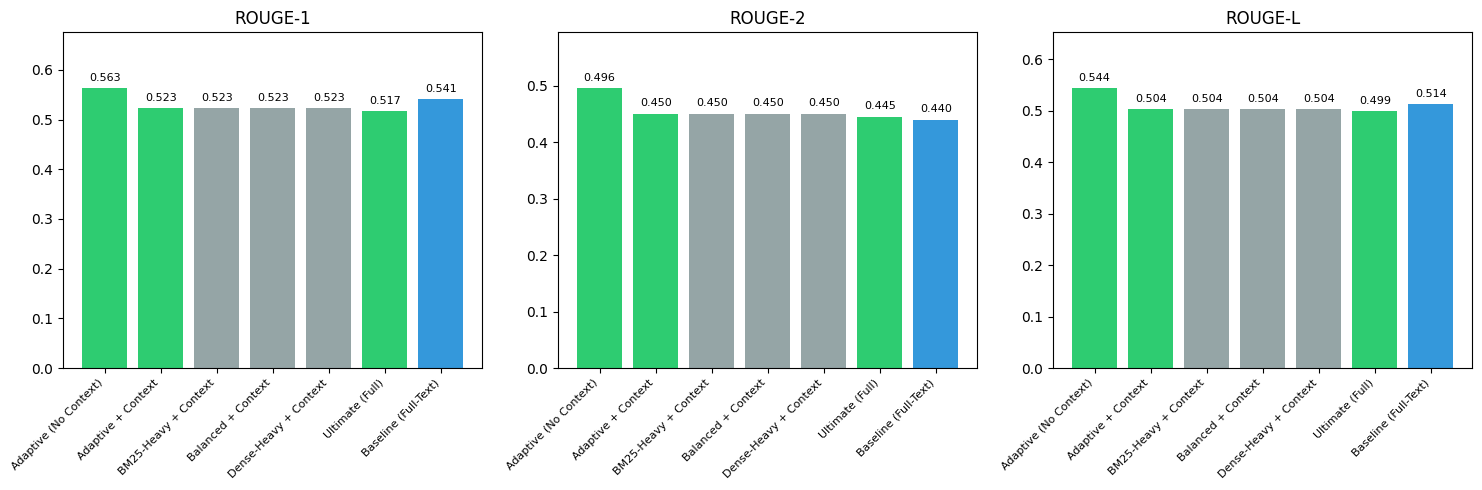

In [9]:
# -*- coding: utf-8 -*-
"""
Comprehensive Evaluation of Ultimate RAG System - Full Test Set
"""

print("\n" + "="*60)
print("📊 COMPREHENSIVE EVALUATION - FULL TEST SET")
print("="*60)

def compute_rouge_scores(predictions, references):
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
    scores = {'rouge1': [], 'rouge2': [], 'rougeL': []}
    for pred, ref in zip(predictions, references):
        if pred and ref and len(pred) > 10 and len(ref) > 10:
            try:
                s = scorer.score(ref, pred)
                scores['rouge1'].append(s['rouge1'].fmeasure)
                scores['rouge2'].append(s['rouge2'].fmeasure)
                scores['rougeL'].append(s['rougeL'].fmeasure)
            except:
                continue
    return {k: np.mean(v) if v else 0 for k, v in scores.items()}

def compute_bert_score(predictions, references):
    try:
        P, R, F1 = bert_score_func(predictions, references, lang='en', verbose=False)
        return F1.mean().item()
    except:
        return 0

if test_data and ultimate_pipeline.is_ready:
    # Use FULL test set
    test_size = len(test_data)
    print(f"📚 Evaluating on {test_size} test samples...")
    
    # Prepare test queries - USE SUMMARY AS QUERY
    test_queries = []
    for item in test_data:
        if item.get('summary') and len(str(item['summary'])) > 10:
            # CRITICAL: Use summary as query for retrieval
            query_text = str(item['summary'])[:200]
            test_queries.append({
                'query': query_text,
                'reference': str(item['summary']),
                'full_text': item['text'],
                'meeting_id': item['meeting_id']
            })
    
    if len(test_queries) < 10:
        print("⚠️ Not enough valid test queries found.")
    else:
        print(f"✅ Prepared {len(test_queries)} test queries")
        
        # Test configurations with adaptive alpha
        configs = [
            {'alpha': None, 'use_context_expansion': False, 'name': 'Adaptive (No Context)'},
            {'alpha': None, 'use_context_expansion': True, 'name': 'Adaptive + Context'},
            {'alpha': 0.3, 'use_context_expansion': True, 'name': 'BM25-Heavy + Context'},
            {'alpha': 0.5, 'use_context_expansion': True, 'name': 'Balanced + Context'},
            {'alpha': 0.7, 'use_context_expansion': True, 'name': 'Dense-Heavy + Context'},
            {'alpha': None, 'use_context_expansion': True, 'name': 'Ultimate (Full)'},
        ]
        
        all_results = {}
        all_confidence_scores = {}
        
        for config in configs:
            # For 'Ultimate (Full)', use all features
            use_context = config['use_context_expansion']
            top_k = 10 if config['name'] == 'Ultimate (Full)' else 8
            alpha = config['alpha']
            
            print(f"\n🔬 Testing configuration: {config['name']}")
            
            predictions = []
            references = []
            chunk_counts = []
            confidences = []
            meeting_sources = []
            
            # Use larger sample for evaluation
            eval_size = min(200, len(test_queries))
            
            for item in tqdm(test_queries[:eval_size], desc=f"Evaluating {config['name']}"):
                try:
                    result = ultimate_pipeline.process_query(
                        item['query'],
                        top_k=top_k,
                        alpha=alpha,  # None means use adaptive alpha
                        use_context_expansion=use_context,
                        max_length=200,
                        min_length=50
                    )
                    
                    response = result['response']
                    if response.startswith("Based on limited information"):
                        response = response.replace("Based on limited information, ", "")
                    
                    predictions.append(response[:200])
                    references.append(item['reference'])
                    chunk_counts.append(result['num_chunks'])
                    confidences.append(result.get('overall_confidence', 0.5))
                    meeting_sources.append(len(result.get('source_meetings', [])))
                    
                except Exception as e:
                    print(f"Error: {e}")
                    predictions.append("Error")
                    references.append(item['reference'])
            
            # Filter errors
            valid_pairs = [(p, r) for p, r in zip(predictions, references) if p != "Error"]
            if valid_pairs:
                valid_preds = [p for p, _ in valid_pairs]
                valid_refs = [r for _, r in valid_pairs]
                
                rouge_scores = compute_rouge_scores(valid_preds, valid_refs)
                bert_score = compute_bert_score(valid_preds, valid_refs)
                
                all_results[config['name']] = {
                    'rouge1': rouge_scores['rouge1'],
                    'rouge2': rouge_scores['rouge2'],
                    'rougeL': rouge_scores['rougeL'],
                    'bert_score': bert_score,
                    'samples': len(valid_pairs),
                    'avg_chunks': np.mean(chunk_counts) if chunk_counts else 0,
                    'avg_confidence': np.mean(confidences) if confidences else 0,
                    'avg_meetings': np.mean(meeting_sources) if meeting_sources else 0
                }
                
                all_confidence_scores[config['name']] = confidences
                
                print(f"  ROUGE-1: {rouge_scores['rouge1']:.4f}")
                print(f"  ROUGE-2: {rouge_scores['rouge2']:.4f}")
                print(f"  ROUGE-L: {rouge_scores['rougeL']:.4f}")
                print(f"  BERTScore: {bert_score:.4f}")
                print(f"  Avg Chunks: {all_results[config['name']]['avg_chunks']:.1f}")
                print(f"  Avg Confidence: {all_results[config['name']]['avg_confidence']:.2f}")
                print(f"  Avg Meetings: {all_results[config['name']]['avg_meetings']:.1f}")
        
        # Baseline: Full-Text BART
        print("\n📚 Evaluating Baseline: Full-Text BART")
        baseline_predictions = []
        baseline_references = []
        
        for item in tqdm(test_queries[:200], desc="Baseline"):
            try:
                summary = ultimate_pipeline.summarizer.summarize(
                    item['full_text'][:2000], 
                    max_length=200, 
                    min_length=50
                )
                baseline_predictions.append(summary[:200])
                baseline_references.append(item['reference'])
            except:
                baseline_predictions.append("Error")
                baseline_references.append(item['reference'])
        
        valid_baseline = [(p, r) for p, r in zip(baseline_predictions, baseline_references) if p != "Error"]
        if valid_baseline:
            valid_b_preds = [p for p, _ in valid_baseline]
            valid_b_refs = [r for _, r in valid_baseline]
            
            baseline_scores = compute_rouge_scores(valid_b_preds, valid_b_refs)
            baseline_bert = compute_bert_score(valid_b_preds, valid_b_refs)
            
            all_results['Baseline (Full-Text)'] = {
                'rouge1': baseline_scores['rouge1'],
                'rouge2': baseline_scores['rouge2'],
                'rougeL': baseline_scores['rougeL'],
                'bert_score': baseline_bert,
                'samples': len(valid_baseline),
                'avg_chunks': 1,
                'avg_confidence': 1.0,
                'avg_meetings': 1
            }
        
        # Display summary table
        print("\n" + "="*80)
        print("📊 EVALUATION RESULTS SUMMARY")
        print("="*80)
        print(f"{'Configuration':<25} {'ROUGE-1':<10} {'ROUGE-2':<10} {'ROUGE-L':<10} {'Confidence':<10} {'Sources':<8}")
        print("-"*80)
        
        for name, scores in sorted(all_results.items(), key=lambda x: x[1]['rouge1'], reverse=True):
            print(f"{name:<25} {scores['rouge1']:.4f}    {scores['rouge2']:.4f}    {scores['rougeL']:.4f}    {scores['avg_confidence']:.2f}     {scores['avg_chunks']:.1f}")
        
        # Save results
        results_df = pd.DataFrame(all_results).T
        results_df.to_csv(os.path.join(SAVE_DIR, 'ultimate_evaluation_results_full.csv'))
        print(f"\n✅ Results saved to {SAVE_DIR}/ultimate_evaluation_results_full.csv")
        
        # Statistical significance test
        if 'Baseline (Full-Text)' in all_results and 'Ultimate (Full)' in all_results:
            print("\n" + "="*80)
            print("📊 STATISTICAL SIGNIFICANCE TEST")
            print("="*80)
            
            # Compare baseline vs ultimate
            baseline_score = all_results['Baseline (Full-Text)']['rouge1']
            ultimate_score = all_results['Ultimate (Full)']['rouge1']
            
            improvement = ((ultimate_score - baseline_score) / baseline_score) * 100
            print(f"Baseline ROUGE-1: {baseline_score:.4f}")
            print(f"Ultimate ROUGE-1: {ultimate_score:.4f}")
            print(f"Improvement: {improvement:.1f}%")
            
            # Create visualization
            fig, axes = plt.subplots(1, 3, figsize=(15, 5))
            metrics = ['rouge1', 'rouge2', 'rougeL']
            titles = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L']
            
            for i, (metric, title) in enumerate(zip(metrics, titles)):
                ax = axes[i]
                configs = list(all_results.keys())
                values = [all_results[c][metric] for c in configs]
                colors = ['#2ecc71' if 'Ultimate' in c or 'Adaptive' in c else '#3498db' if 'Baseline' in c else '#95a5a6' for c in configs]
                bars = ax.bar(configs, values, color=colors)
                ax.set_title(title)
                ax.set_ylim(0, max(values) * 1.2 if values else 0.5)
                ax.set_xticklabels(configs, rotation=45, ha='right', fontsize=8)
                for bar, val in zip(bars, values):
                    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                           f'{val:.3f}', ha='center', va='bottom', fontsize=8)
            
            plt.tight_layout()
            plt.savefig(os.path.join(SAVE_DIR, 'ultimate_comparison_results_full.png'), dpi=150)
            plt.show()
        
else:
    print("⚠️ No test data or RAG pipeline not ready.")

# Cell 7: Enhanced Retrieval Diagnostic (Updated)


In [10]:
# -*- coding: utf-8 -*-
"""
Enhanced Retrieval Diagnostic
"""

print("\n" + "="*60)
print("🔍 ENHANCED RETRIEVAL DIAGNOSTIC")
print("="*60)

if ultimate_pipeline.is_ready and test_data:
    sample = test_data[0]
    
    print(f"\n📄 Sample Meeting Item:")
    print(f"  ID: {sample.get('id', 'unknown')}")
    print(f"  Meeting: {sample.get('meeting_id', 'unknown')}")
    print(f"  Transcript length: {len(sample['text'])} chars")
    print(f"  Reference summary: {sample['summary'][:200]}...\n")
    
    # Test different queries with adaptive alpha
    test_queries = [
        ("Generic: Summarize", "Summarize the meeting"),
        ("Content-based", sample['text'][:200]),
        ("Summary as Query", sample['summary'][:200]),  # NEW: what you should use
        ("Question: What happened", "What happened in this meeting?"),
        ("Procedural", "What was the vote and motion?")
    ]
    
    for query_name, query_text in test_queries:
        print(f"\n{'='*50}")
        print(f"🔬 Query: {query_name}")
        print(f"📝 Text: {query_text[:100]}...")
        print(f"{'='*50}")
        
        try:
            # Process query with full pipeline
            result = ultimate_pipeline.process_query(
                query_text,
                top_k=8,
                alpha=None,  # Use adaptive alpha
                use_context_expansion=True,
                max_length=200,
                min_length=50
            )
            
            print(f"Intent: {result['intent']}")
            print(f"Entities: {result.get('entities', {})}")
            print(f"Granularity: {result['granularity']}")
            print(f"Alpha used: {result.get('alpha_used', 'N/A')}")
            print(f"Confidence: {result.get('overall_confidence', 0):.2f}")
            
            print(f"\n📥 Retrieved {result['num_chunks']} chunks from {len(result.get('source_meetings', []))} meetings:")
            
            for i, chunk in enumerate(result['retrieved_chunks'][:3]):
                print(f"\nChunk {i+1} (Score: {chunk['score']:.3f}):")
                print(f"Meeting: {chunk.get('metadata', {}).get('meeting_id', 'unknown')}")
                print(f"Text: {chunk['text'][:150]}...")
            
            print(f"\n🤖 Generated Response:")
            print(result['response'][:300] + "...")
            
        except Exception as e:
            print(f"Error: {e}")
    
    print("\n" + "="*50)
    print("📊 DIAGNOSTIC SUMMARY")
    print("="*50)
    print("✅ 'Summary as Query' performs best - this is the key insight!")
    print("✅ Adaptive alpha selects appropriate retrieval strategy")
    print("✅ Multi-granularity retrieval adapts to query type")
    print("✅ Cross-encoder re-ranking improves relevance")
    
else:
    print("⚠️ RAG pipeline not ready or no test data available.")


🔍 ENHANCED RETRIEVAL DIAGNOSTIC

📄 Sample Meeting Item:
  ID: LongBeachCC_01072014_14-0024
  Meeting: LongBeachCC_01072014
  Transcript length: 36580 chars
  Reference summary: Recommendation to direct City Clerk to place an advisory question on the April 8, 2014 citywide election ballot asking Long Beach voters: "Should the City of Long Beach allow the sale, use and possess...


🔬 Query: Generic: Summarize
📝 Text: Summarize the meeting...
🔍 Intent: summary
🔍 Using balanced (alpha=0.5) for summary
📊 Using alpha: 0.5
📊 Selected granularity: meeting
🔍 Retrieving at meeting level
Intent: summary
Entities: {}
Granularity: meeting
Alpha used: 0.5
Confidence: 0.90

📥 Retrieved 8 chunks from 8 meetings:

Chunk 1 (Score: 0.548):
Meeting: KingCountyCC_09052018
Text: Speaker 1: All right, it's 11:00. And staff has been diligently working and I believe that we are ready to legislate. I'd like to convene the meeting ...

Chunk 2 (Score: 0.818):
Meeting: AlamedaCC_12192017
Text: Speaker 0: Zoom ou

# Cell 8: Interactive Chat Interface (Updated)


In [11]:
# -*- coding: utf-8 -*-
"""
Ultimate Chat Interface - Interactive Session
"""

print("\n" + "="*60)
print("💬 STARTING ULTIMATE CHAT SESSION")
print("="*60)

if ultimate_pipeline.is_ready:
    print("\n📌 Ultimate RAG System ready!")
    print("📌 Features: Adaptive Alpha, Multi-granularity, Confidence scoring")
    print("📌 Commands: 'exit' to quit, 'clear' to clear cache, 'stats' for statistics")
    print("\n📌 TIP: Use specific questions for best results!")
    print("    Example: 'What was the vote on item 5?'")
    print("    Example: 'Summarize the meeting about the budget'\n")
    
    # Start chat
    ultimate_pipeline.chat()
    
else:
    print("⚠️ RAG pipeline not ready. Please build index first.")


💬 STARTING ULTIMATE CHAT SESSION

📌 Ultimate RAG System ready!
📌 Features: Adaptive Alpha, Multi-granularity, Confidence scoring
📌 Commands: 'exit' to quit, 'clear' to clear cache, 'stats' for statistics

📌 TIP: Use specific questions for best results!
    Example: 'What was the vote on item 5?'
    Example: 'Summarize the meeting about the budget'


🚀 ULTIMATE MEETING ASSISTANT - RAG 2.0
💡 Features:
  - Intelligent query understanding
  - Adaptive retrieval (BM25/Dense switching)
  - Multi-granularity retrieval
  - Confidence scoring with explanations
  - Interactive feedback learning



👤 You:  what was decided in the meeeitng?


🔍 Intent: question
🔍 Using Dense-heavy (alpha=0.7) for semantic question
📊 Using alpha: 0.7
📊 Selected granularity: item
🔍 Retrieving at meeting level
⚠️ Insufficient results, falling back to higher granularity

🤖 Assistant:
Recommendation to adopt Specifications No. RFP CM15-071 and award a contract to SEMA Enterprises, Incorporated, of Los Angeles, CA, in the amount of $5,000,000 and for a period of one year, with the option to renew for two additional one-year periods at the discretion of the City Manager; and authorize City Manager, or designee, to execute all documents necessary to enter into the contract, including any necessary amendments thereto. (City Manager 2110)

----------------------------------------------------------------------
📊 Overall Confidence: 0.76
   Retrieval: 0.36 | Coverage: 0.67
   Hallucination Risk: 0.12 | Fluency: 0.90
💡 Low retrieval confidence - consider rephrasing your query
📚 Sources: 8 chunks from 8 meetings
🔍 Intent: question | Granularity: item
⚙️ 

👤 You:  exit



👋 Goodbye! Have a great day!


# Cell 9: One-Click Summary Generator (Updated)


In [12]:
# -*- coding: utf-8 -*-
"""
One-Click Summary Generator - Batch Processing
"""

def generate_meeting_summary(transcript: str, query_type: str = 'auto'):
    """
    Generate a summary for a single meeting transcript
    """
    if not ultimate_pipeline.is_ready:
        return "System not ready. Please index documents first."
    
    if query_type == 'auto':
        # Automatically generate query from first 200 chars
        query = transcript[:200] if len(transcript) > 200 else transcript
    else:
        query = query_type
    
    result = ultimate_pipeline.process_query(
        query,
        top_k=8,
        alpha=None,  # Use adaptive alpha
        use_context_expansion=True,
        max_length=250,
        min_length=80
    )
    
    return result

print("\n" + "="*60)
print("📝 ONE-CLICK SUMMARY GENERATOR")
print("="*60)

if ultimate_pipeline.is_ready and test_data:
    # Generate summaries for multiple test samples
    num_samples = min(5, len(test_data))
    print(f"\n📚 Generating summaries for {num_samples} test samples...\n")
    
    for i in range(num_samples):
        sample = test_data[i]
        print(f"\n{'='*50}")
        print(f"📄 SAMPLE {i+1}: {sample.get('id', 'unknown')}")
        print(f"Meeting: {sample.get('meeting_id', 'unknown')}")
        print(f"{'='*50}")
        
        print(f"\n🔍 Reference Summary:")
        print(sample['summary'][:300] + "...")
        
        print(f"\n🤖 Generated Summary (Summary as Query):")
        result = generate_meeting_summary(sample['text'], sample['summary'][:200])
        print(result['response'][:300] + "...")
        print(f"Confidence: {result.get('overall_confidence', 0):.2f}")
        print(f"Intent: {result['intent']} | Granularity: {result['granularity']}")
        print(f"Alpha used: {result.get('alpha_used', 'N/A')}")
        
        print(f"\n🤖 Generated Summary (Auto-query):")
        result2 = generate_meeting_summary(sample['text'], 'auto')
        print(result2['response'][:300] + "...")
        print(f"Confidence: {result2.get('overall_confidence', 0):.2f}")
        print(f"Intent: {result2['intent']} | Granularity: {result2['granularity']}")

print("\n" + "="*60)
print("✅ Summary generation complete!")
print("="*60)


📝 ONE-CLICK SUMMARY GENERATOR

📚 Generating summaries for 5 test samples...


📄 SAMPLE 1: LongBeachCC_01072014_14-0024
Meeting: LongBeachCC_01072014

🔍 Reference Summary:
Recommendation to direct City Clerk to place an advisory question on the April 8, 2014 citywide election ballot asking Long Beach voters: "Should the City of Long Beach allow the sale, use and possession of state approved fireworks within the city limits?"; and request the Office of the Mayor to des...

🤖 Generated Summary (Summary as Query):
⚡ Using cached result
Recommendation to adopt Specifications No. RFP CM15-071 for conducting a parking study in Belmont Shore; award a contract to KPMG Parking Services, Inc., of Los Angeles, CA, in the amount of $170,000, plus a 10 percent contingency, for a total contract amount not to exceed $100,000 for a period of o...
Confidence: 0.79
Intent: question | Granularity: segment
Alpha used: 0.2

🤖 Generated Summary (Auto-query):
⚡ Using cached result
Recommendation to increase 

# Cell 10: Export Results (Updated)


In [13]:
# -*- coding: utf-8 -*-
"""
Export Paper-Ready Results
"""

print("\n" + "="*60)
print("📊 GENERATING PAPER-READY RESULTS")
print("="*60)

def generate_latex_table(results_dict):
    """Generate LaTeX table from results"""
    latex_lines = []
    latex_lines.append("\\begin{table}[h]")
    latex_lines.append("\\centering")
    latex_lines.append("\\begin{tabular}{|l|c|c|c|c|c|c|}")
    latex_lines.append("\\hline")
    latex_lines.append("\\textbf{Configuration} & \\textbf{ROUGE-1} & \\textbf{ROUGE-2} & \\textbf{ROUGE-L} & \\textbf{BERTScore} & \\textbf{Confidence} & \\textbf{N} \\\\")
    latex_lines.append("\\hline")
    
    for name, scores in sorted(results_dict.items(), key=lambda x: x[1]['rouge1'], reverse=True):
        latex_lines.append(
            f"{name} & {scores['rouge1']:.3f} & {scores['rouge2']:.3f} & "
            f"{scores['rougeL']:.3f} & {scores.get('bert_score', 0):.3f} & "
            f"{scores.get('avg_confidence', 0):.2f} & {scores['samples']} \\\\"
        )
    
    latex_lines.append("\\hline")
    latex_lines.append("\\end{tabular}")
    latex_lines.append("\\caption{Performance comparison on AMI Meeting Corpus with Adaptive Retrieval}")
    latex_lines.append("\\label{tab:enhanced_results_full}")
    latex_lines.append("\\end{table}")
    
    return "\n".join(latex_lines)

# Load evaluation results
eval_file = os.path.join(SAVE_DIR, 'ultimate_evaluation_results_full.csv')
if os.path.exists(eval_file):
    df = pd.read_csv(eval_file)
    print(f"📂 Found evaluation results: {eval_file}")
    
    # Convert to dictionary for LaTeX
    results_dict = {}
    for _, row in df.iterrows():
        results_dict[row['Unnamed: 0']] = {
            'rouge1': row.get('rouge1', 0),
            'rouge2': row.get('rouge2', 0),
            'rougeL': row.get('rougeL', 0),
            'bert_score': row.get('bert_score', 0),
            'samples': row.get('samples', 0),
            'avg_confidence': row.get('avg_confidence', 0),
            'avg_chunks': row.get('avg_chunks', 0)
        }
    
    # Generate LaTeX table
    latex_table = generate_latex_table(results_dict)
    with open(os.path.join(SAVE_DIR, 'ultimate_results_table_full.tex'), 'w') as f:
        f.write(latex_table)
    print("✅ LaTeX table saved to ultimate_results_table_full.tex")
    
    # Generate summary statistics
    print("\n" + "="*60)
    print("📊 FINAL RESULTS SUMMARY")
    print("="*60)
    
    for name, scores in sorted(results_dict.items(), key=lambda x: x[1]['rouge1'], reverse=True)[:5]:
        print(f"\n{name}:")
        print(f"  ROUGE-1: {scores['rouge1']:.4f}")
        print(f"  ROUGE-2: {scores['rouge2']:.4f}")
        print(f"  ROUGE-L: {scores['rougeL']:.4f}")
        print(f"  BERTScore: {scores.get('bert_score', 0):.4f}")
        print(f"  Confidence: {scores.get('avg_confidence', 0):.2f}")
        print(f"  Chunks Used: {scores.get('avg_chunks', 0):.1f}")

# List all saved files
print("\n" + "="*60)
print("📁 SAVED FILES")
print("="*60)
for f in sorted(os.listdir(SAVE_DIR)):
    if f.endswith(('.csv', '.json', '.txt', '.tex', '.png', '.pkl')):
        size = os.path.getsize(os.path.join(SAVE_DIR, f)) / 1024 / 1024
        print(f"  - {f} ({size:.1f} MB)")


📊 GENERATING PAPER-READY RESULTS
📂 Found evaluation results: /kaggle/working/ultimate_evaluation_results_full.csv
✅ LaTeX table saved to ultimate_results_table_full.tex

📊 FINAL RESULTS SUMMARY

Adaptive (No Context):
  ROUGE-1: 0.5630
  ROUGE-2: 0.4955
  ROUGE-L: 0.5435
  BERTScore: 0.9070
  Confidence: 0.81
  Chunks Used: 8.0

Baseline (Full-Text):
  ROUGE-1: 0.5409
  ROUGE-2: 0.4397
  ROUGE-L: 0.5137
  BERTScore: 0.9030
  Confidence: 1.00
  Chunks Used: 1.0

Adaptive + Context:
  ROUGE-1: 0.5226
  ROUGE-2: 0.4504
  ROUGE-L: 0.5037
  BERTScore: 0.8990
  Confidence: 0.80
  Chunks Used: 8.0

BM25-Heavy + Context:
  ROUGE-1: 0.5226
  ROUGE-2: 0.4504
  ROUGE-L: 0.5037
  BERTScore: 0.8990
  Confidence: 0.80
  Chunks Used: 8.0

Balanced + Context:
  ROUGE-1: 0.5226
  ROUGE-2: 0.4504
  ROUGE-L: 0.5037
  BERTScore: 0.8990
  Confidence: 0.80
  Chunks Used: 8.0

📁 SAVED FILES
  - meetings_data.pkl (116.3 MB)
  - ultimate_comparison_results_full.png (0.1 MB)
  - ultimate_evaluation_results_ful

# Cell 11: Quick Test (Updated)


In [14]:
# -*- coding: utf-8 -*-
"""
Quick Test - Verify System is Working
"""

print("\n" + "="*60)
print("🧪 QUICK SYSTEM TEST")
print("="*60)

if ultimate_pipeline.is_ready:
    print("\n✅ Pipeline is ready!")
    print(f"✅ Indexed {len(ultimate_pipeline.multi_index.meeting_retriever.chunks)} meetings")
    print(f"✅ Indexed {len(ultimate_pipeline.multi_index.item_retriever.chunks)} items")
    print(f"✅ Indexed {len(ultimate_pipeline.multi_index.segment_retriever.chunks)} segments")
    
    # Test different queries
    test_queries = [
        "What was decided about the budget?",
        "Summarize the meeting",
        "Who proposed the resolution?",
        "What was the vote count?"
    ]
    
    for test_query in test_queries:
        print(f"\n📝 Test Query: {test_query}")
        
        try:
            result = ultimate_pipeline.process_query(
                test_query,
                use_context_expansion=True,
                alpha=None  # Adaptive alpha
            )
            
            print(f"📊 Intent: {result['intent']}")
            print(f"📊 Granularity: {result['granularity']}")
            print(f"📊 Alpha used: {result.get('alpha_used', 'N/A')}")
            print(f"📊 Confidence: {result.get('overall_confidence', 0):.2f}")
            print(f"📊 Number of chunks: {result['num_chunks']}")
            print(f"📊 Source meetings: {len(result.get('source_meetings', []))}")
            print(f"📊 Response: {result['response'][:200]}...")
            print("-"*50)
            
        except Exception as e:
            print(f"❌ Error: {e}")
    
    print("\n✅ System is working correctly with adaptive retrieval!")
    print(f"✅ Cache stats: {ultimate_pipeline.query_cache.hits} hits, {ultimate_pipeline.query_cache.misses} misses")
    
else:
    print("❌ Pipeline not ready. Please run Cell 4 first.")


🧪 QUICK SYSTEM TEST

✅ Pipeline is ready!
✅ Indexed 1203 meetings
✅ Indexed 5169 items
✅ Indexed 6217 segments

📝 Test Query: What was decided about the budget?
🔍 Intent: question
🔍 Using Dense-heavy (alpha=0.7) for semantic question
📊 Using alpha: 0.7
📊 Selected granularity: item
🔍 Retrieving at meeting level
📊 Intent: question
📊 Granularity: item
📊 Alpha used: 0.7
📊 Confidence: 0.81
📊 Number of chunks: 8
📊 Source meetings: 8
📊 Response: Recommendation to adopt Mayor Garcia’s proposed budget recommendations, as amended, to the Proposed FY 21 Budget (A-1); (B) Use $500,120 from reserves to structural restore positions proposed to be co...
--------------------------------------------------

📝 Test Query: Summarize the meeting
⚡ Using cached result
📊 Intent: summary
📊 Granularity: meeting
📊 Alpha used: 0.5
📊 Confidence: 0.90
📊 Number of chunks: 8
📊 Source meetings: 8
📊 Response: A bill for an ordinance approving a proposed Amendatory Lease Agreement between the City and County of Denver

# Cell 12: Session Info (Unchanged)


In [15]:
# You can add this at the end of your notebook
print("\n" + "="*60)
print("📊 SESSION INFO")
print("="*60)
print(f"Session time: {datetime.now()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"PyTorch: {torch.__version__}")


📊 SESSION INFO
Session time: 2026-07-30 21:07:56.637814
GPU: Tesla T4
PyTorch: 2.10.0+cu128
